# Detecting Fraudulent Websites from the URL and its Page Signals

### F21DL Data Mining and Machine Learning - Group Coursework

| Item | Detail |
|---|---|
| **Project title** | Trust or trick? Detecting fraudulent and scam websites from URL and page signals |
| **Coursework topic** | Topic 11 - Predict whether a website is fraudulent/scam |
| **Dataset** | PhiUSIIL Phishing URL Dataset, UCI Machine Learning Repository (dataset ID 967) |
| **Dataset licence** | CC BY 4.0 - Prasad and Chandra (2024) |
| **GitHub repository** | https://github.com/Sakib-Dalal/DMML-CourseWork01 |
| **Notebook** | `DataMining&MachineLearning_Coursework_01.ipynb` |

All of the work for requirements **R1 to R4** is contained in this one notebook.
Every section starts with a short plain-English explanation of what is being done
and why, followed by the code that does it.

## Index

| Step | Section | Coursework requirement |
|---|---|---|
| 1 | Research questions and hypotheses | **R1** |
| 2 | Imports and global settings | setup |
| 3 | Loading the dataset | R2 |
| 4 | First look at the data | R2 |
| 5 | Data cleaning and preprocessing | **R2** |
| 6 | Exploratory data analysis and visualisation | **R2** |
| 7 | Feature selection and evaluation (three methods) | **R2** |
| 8 | Train/test split and feature scaling | R2 |
| 9 | Clustering: K-Means and Gaussian Mixture (EM) | **R2** |
| 10 | Baseline classical models | **R3** |
| 11 | Decision trees in practice | **R3** |
| 12 | Neural networks: MLP, BERT-lite and a character CNN | **R4** |
| 13 | Final comparison of every model | R3 + R4 |
| 14 | Conclusions, limitations and references | all |

### How the notebook maps onto the marking criteria

| Requirement | What the brief asks for | Where it is answered |
|---|---|---|
| R1 | Clear questions, objectives and hypotheses | Step 1 |
| R2 | Cleaning, EDA with visualisation, feature selection and evaluation, clustering with metrics | Steps 3-9 |
| R3 | At least three classical ML algorithms compared with appropriate metrics, plus a discussion of decision trees | Steps 10-11 |
| R4 | Neural network models, trained, tuned and compared against the classical models | Steps 12-13 |

## Summary of findings

The full analysis is in the steps below; this table is the short version.

| Question | Answer |
|---|---|
| Can phishing be separated from legitimate sites? | Yes, nearly completely. The best model reaches F1 = 0.9986 on features that do not encode the label. |
| Which features carry the signal? | Page structure, not URL length: page size, the internal/external reference counts, and the boilerplate flags (`HasSocialNet`, `HasCopyrightInfo`, `HasDescription`). |
| Is HTTPS a useful signal? | Only one way. Every legitimate site has it, but half of the phishing sites do too. |
| Do clusters recover the classes? | Yes. K-Means ARI 0.881, Gaussian mixture (EM) ARI 0.915 - far better than expected, though EM is fragile under random initialisation. |
| Do neural networks win? | No. The MLP matches the linear model and trails the ensembles. On the raw URL text a character CNN beats a frozen two-layer BERT, which is the most interesting result in the notebook. |
| Is the dataset honest? | Not entirely. Three supplied columns compare the URL against the brand's official URL and come close to restating the label. Both settings are reported (Step 10). |

Models are trained on a stratified 24,000-row sample so the notebook runs end to end in a
few minutes on a laptop; the limitation is discussed in Step 14.

# Step 1: Research questions and hypotheses (R1)

### The problem in plain English

A phishing website is a fake page built to look like a real one - a bank, a
delivery company, a payment provider - so that a person types in a password or a
card number and the attacker keeps it. Phishing kits can be set up in minutes and
taken down just as quickly, so a security team cannot rely on a human reading a
list of URLs. Something has to score each website automatically and put the
suspicious ones into a review queue.

Two very different kinds of evidence are available, and that is what makes this
topic interesting:

1. **The URL string itself.** It is short, free to obtain, and available *before*
   anybody visits the page.
2. **Signals taken from the page behind the URL.** How long the page source is,
   whether it has a password field, whether it loads scripts from elsewhere,
   whether the page title matches the domain name, and so on.

The dataset used here contains both, so the project can ask which kind of evidence
actually carries the signal.

### Research questions

* **RQ1** - How accurately can supervised models separate phishing from legitimate
  websites using the tabular features extracted from each URL and its page?
* **RQ2** - Which features carry the signal? Are they the cheap structural ones
  (URL length, number of sub-domains, HTTPS), or the page-level ones (page size,
  number of external references, title match score)?
* **RQ3** - Do the clusters an unsupervised algorithm finds on its own line up with
  the real phishing/legitimate label, and how closely?
* **RQ4** - Does a neural network beat the classical models on this data, and does a
  pretrained language model (BERT) reading the raw URL text add anything on top of
  the engineered features?

### Hypotheses

* **H1** - The engineered features will already give very high accuracy (above 95%),
  because phishing pages differ from ordinary pages in structural ways that a
  decision tree can pick up.
* **H2** - The page-level features will dominate the ranking. A phishing page is
  usually a single thin HTML file that pulls its resources from elsewhere.
* **H3** - Unsupervised clusters will partly recover the label but not perfectly,
  because a legitimate small business site and a phishing page can look structurally
  similar from the outside. A moderate adjusted Rand index is expected, not a near 1.
* **H4** - A neural network will match but not clearly beat the tree ensembles on
  tabular data, because the relationship is mostly a set of threshold rules. A
  pretrained language model reading only the URL text should be weaker than the
  full feature set, because it cannot see the page at all.

### An important caveat discovered during the analysis

Three of the supplied features are computed by comparing the URL against the
*official* URL or title of the brand it claims to belong to. For a legitimate site
that comparison is trivially perfect, so these columns come close to encoding the
label itself. Step 7 identifies them, and Step 10 therefore reports every model
twice: once on the full feature set (the ceiling) and once with those three columns
removed (a realistic deployment). Reporting both is the honest thing to do; a
single table showing 100% everywhere would hide the problem.

# Step 2: Imports and global settings

The stack used is the one recommended for the course:

* **pandas** to hold the data in a table (a *DataFrame*),
* **numpy** for numerical work,
* **scikit-learn** for preprocessing, models and metrics,
* **matplotlib** and **seaborn** for graphs,
* **torch** and **transformers** for the neural network section (R4).

One random seed is fixed everywhere so the notebook reproduces the same numbers on
every run.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
os.environ["TRANSFORMERS_VERBOSITY"] = "error"

In [2]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

SAMPLE_SIZE = 24000      # rows used for modelling - the full file has about 236k
TEST_SIZE = 0.30         # 70% train, 30% test
CLASS_NAMES = ["Phishing", "Legitimate"]

# these three columns are computed against the brand's official URL or title,
# so they behave almost like a copy of the label. Step 7 explains this in detail.
SIMILARITY_FEATURES = ["URLSimilarityIndex", "URLTitleMatchScore", "DomainTitleMatchScore"]

# Step 3: Loading the dataset

The PhiUSIIL dataset is a single CSV file stored in the `Datasets` folder of the
repository, next to this notebook.

Instead of hard-coding an absolute path, the helper below walks up from the current
working directory until it finds `Datasets/<file name>`. The notebook therefore runs
from any folder inside the project without edits.

In [3]:
DATASET_FILE = "PhiUSIIL_Phishing_URL_Dataset.csv"


def find_dataset(filename):
    folder = os.getcwd()
    for _ in range(5):
        candidate = os.path.join(folder, "Datasets", filename)
        if os.path.exists(candidate):
            return candidate
        folder = os.path.dirname(folder)
    raise FileNotFoundError("Could not find Datasets/" + filename)


DATA_PATH = find_dataset(DATASET_FILE)
print("Dataset path:", DATA_PATH)

Dataset path: /Users/sakibdalal/Projects/DMML-CourseWork01/Datasets/PhiUSIIL_Phishing_URL_Dataset.csv


In [4]:
df = pd.read_csv(DATA_PATH)

print("Rows    :", df.shape[0])
print("Columns :", df.shape[1])

Rows    : 235795
Columns : 56


In [5]:
df.head()

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,3,1,0,0,0.0,18,0.581,0,0.0,0,0,0,1,0.032,1,558,9381,1,à¸‚à¹ˆà¸²à¸§à¸ªà¸” à¸‚à¹ˆà¸²à¸§à¸§à¸±à¸™à¸™à¸µ...,0.000000,0.000000,0,1,1,0,0,0,0,1,0,0,1,1,0,1,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,2,1,0,0,0.0,9,0.391,0,0.0,0,0,0,2,0.087,1,618,9381,1,johannes gutenberg-universitÃ¤t mainz,55.555556,55.555556,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,2,2,0,0,0.0,15,0.517,0,0.0,0,0,0,2,0.069,1,467,682,1,voice fm southampton,46.666667,46.666667,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,3,1,0,0,0.0,13,0.500,0,0.0,0,0,0,1,0.038,1,6356,26824,1,home page: seminars in fetal and neonatal medi...,0.000000,0.000000,0,1,1,0,0,0,1,12,0,1,1,1,0,0,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,3,1,0,0,0.0,20,0.606,0,0.0,0,0,0,1,0.030,1,6089,28404,1,fundaciÃ³n rewilding argentina,100.000000,100.000000,0,1,1,1,1,1,0,2,0,1,1,1,0,1,1,0,1,244,15,34,72,1,85,1


### What the columns mean

* `FILENAME` - an identifier for the captured page. Contains no information, so it is dropped.
* `URL` - the raw URL string. Kept, because the BERT section reads it.
* `label` - **1 = legitimate, 0 = phishing**. This is the target.
* The other 51 columns are numbers extracted from the URL and from the page source.
  They fall into four groups:
  * **Lexical URL features** - `URLLength`, `NoOfSubDomain`, `IsHTTPS`,
    `NoOfObfuscatedChar`, `SpacialCharRatioInURL`. These describe the text of the URL.
  * **Domain and TLD features** - `TLD`, `TLDLength`, `IsDomainIP`,
    `TLDLegitimateProb`, which describe the registered domain.
  * **Similarity scores** - `URLSimilarityIndex`, `DomainTitleMatchScore`,
    `URLTitleMatchScore`. These compare the URL with the official brand URL or with
    the page title. They are discussed again in Step 7.
  * **Page-structure features** - `LineOfCode`, `NoOfImage`, `NoOfCSS`, `NoOfJS`,
    `HasPasswordField`, `NoOfExternalRef`. These describe what the page is made of.

# Step 4: First look at the data

Before changing anything, three things are checked: the data types, the summary
statistics, and whether the two classes are balanced.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  str    
 1   URL                         235795 non-null  str    
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  str    
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  str    
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  HasObfuscation           

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
URLLength,235795.0,34.573095,41.314153,13.000000,23.000000,27.000000,34.000000,6.097000e+03
DomainLength,235795.0,21.470396,9.150793,4.000000,16.000000,20.000000,24.000000,1.100000e+02
IsDomainIP,235795.0,0.002706,0.051946,0.000000,0.000000,0.000000,0.000000,1.000000e+00
URLSimilarityIndex,235795.0,78.430778,28.976055,0.155574,57.024793,100.000000,100.000000,1.000000e+02
CharContinuationRate,235795.0,0.845508,0.216632,0.000000,0.680000,1.000000,1.000000,1.000000e+00
TLDLegitimateProb,235795.0,0.260423,0.251628,0.000000,0.005977,0.079963,0.522907,5.229071e-01
URLCharProb,235795.0,0.055747,0.010587,0.001083,0.050747,0.057970,0.062875,9.082366e-02
TLDLength,235795.0,2.764456,0.599739,2.000000,2.000000,3.000000,3.000000,1.300000e+01
NoOfSubDomain,235795.0,1.164758,0.600969,0.000000,1.000000,1.000000,1.000000,1.000000e+01
HasObfuscation,235795.0,0.002057,0.045306,0.000000,0.000000,0.000000,0.000000,1.000000e+00


In [8]:
df["label"].value_counts()

label
1    134850
0    100945
Name: count, dtype: int64

There are 134,850 legitimate websites and 100,945 phishing websites, so the classes
are roughly 57% / 43%. That is only mildly imbalanced, and far kinder than most real
security datasets, which are often 99% one class. Every model is still scored with
precision, recall and F1 rather than accuracy alone, and the split is stratified so
both parts keep the same class ratio.

### Checking the data types

scikit-learn needs every input feature to be a number. The text columns are
identified here so they can be handled deliberately rather than accidentally.

In [9]:
text_columns = ["FILENAME", "URL", "Domain", "TLD", "Title"]
for column in text_columns:
    print(column, "->", df[column].dtype, "|", df[column].nunique(), "distinct values")

FILENAME -> str | 235795 distinct values
URL -> str | 235370 distinct values
Domain -> str | 220086 distinct values
TLD -> str | 695 distinct values
Title -> str | 197874 distinct values


# Step 5: Data cleaning and preprocessing (R2)

Five cleaning decisions are made, each with its reason.

1. **Remove duplicate URLs.** The same page can be captured more than once. Keeping
   copies would let one example appear in both the training and the test set, which
   makes the test score look better than it is. This is called *leakage*.
2. **Check for missing values.** A missing value would have to be imputed, and
   imputation invents information.
3. **Drop columns holding a single value.** Such a column cannot separate the classes
   and only adds noise.
4. **Drop identifier and free-text columns** (`FILENAME`, `Domain`, `Title`). They are
   not numeric features. `Domain` is redundant because it is contained in the URL, and
   `Title` is free text that would need its own model.
5. **Encode the TLD as a number**, because the top-level domain is a genuine signal
   (`xyz` behaves differently from `gov`) and every model here needs numbers.

The `URL` column is not dropped: it is *popped* out into its own Series so that it
can be re-attached to exactly the right rows later. Keeping the row order aligned
between the features and the raw URLs matters, and getting it wrong silently
produces nonsense in Step 12 - so the next two steps are written to make the
alignment explicit.

In [10]:
print("Duplicate rows  :", df.duplicated().sum())
print("Duplicate URLs  :", df["URL"].duplicated().sum())

df = df.drop_duplicates(subset="URL").reset_index(drop=True)
print("Rows after removing duplicate URLs:", len(df))

Duplicate rows  : 0
Duplicate URLs  : 425
Rows after removing duplicate URLs: 235370


In [11]:
missing = df.isna().sum()
print("Total missing values:", missing.sum())
print(missing[missing > 0])

Total missing values: 0
Series([], dtype: int64)


There are no missing values, so no imputation is needed. That is unusual and worth
stating in the report: the dataset creator dropped incomplete captures instead of
patching them.

In [12]:
constant_columns = [column for column in df.columns if df[column].nunique() == 1]
print("Columns with a single value:", constant_columns)

df = df.drop(columns=constant_columns)
print("Shape after removing constant columns:", df.shape)

Columns with a single value: []
Shape after removing constant columns: (235370, 56)


In [13]:
# the raw URL is moved out into its own Series, keeping the same row index
url_table = df.pop("URL")

# these are identifiers or free text, not numeric features
df = df.drop(columns=["FILENAME", "Domain", "Title"])

print("Shape of the numeric table:", df.shape)
print("Rows in the URL table     :", len(url_table))

Shape of the numeric table: (235370, 52)
Rows in the URL table     : 235370


In [14]:
from sklearn.preprocessing import LabelEncoder

tld_encoder = LabelEncoder()
df["TLDCode"] = tld_encoder.fit_transform(df["TLD"])
df = df.drop(columns=["TLD"])

print("Shape after encoding TLD:", df.shape)

Shape after encoding TLD: (235370, 52)


In [15]:
for name, values in df.items():
    print(name, "->", values.dtype)

URLLength -> int64
DomainLength -> int64
IsDomainIP -> int64
URLSimilarityIndex -> float64
CharContinuationRate -> float64
TLDLegitimateProb -> float64
URLCharProb -> float64
TLDLength -> int64
NoOfSubDomain -> int64
HasObfuscation -> int64
NoOfObfuscatedChar -> int64
ObfuscationRatio -> float64
NoOfLettersInURL -> int64
LetterRatioInURL -> float64
NoOfDegitsInURL -> int64
DegitRatioInURL -> float64
NoOfEqualsInURL -> int64
NoOfQMarkInURL -> int64
NoOfAmpersandInURL -> int64
NoOfOtherSpecialCharsInURL -> int64
SpacialCharRatioInURL -> float64
IsHTTPS -> int64
LineOfCode -> int64
LargestLineLength -> int64
HasTitle -> int64
DomainTitleMatchScore -> float64
URLTitleMatchScore -> float64
HasFavicon -> int64
Robots -> int64
IsResponsive -> int64
NoOfURLRedirect -> int64
NoOfSelfRedirect -> int64
HasDescription -> int64
NoOfPopup -> int64
NoOfiFrame -> int64
HasExternalFormSubmit -> int64
HasSocialNet -> int64
HasSubmitButton -> int64
HasHiddenFields -> int64
HasPasswordField -> int64
Bank 

Every column is numeric and there are no missing values, so the table is ready for
analysis.

# Step 6: Exploratory data analysis and visualisation (R2)

The purpose of this section is to answer one question: **do the two classes actually
look different, and in which features?** Each plot below supports a claim written
next to it.

The analysis starts with the class balance, then looks at the distribution of
individual features per class, and ends with the correlation between each feature
and the label.

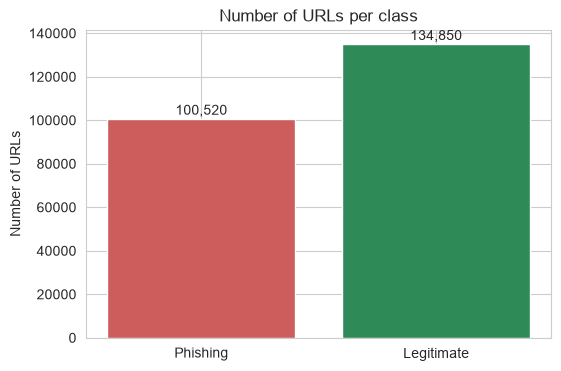

In [16]:
counts = df["label"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(CLASS_NAMES, counts.values, color=["indianred", "seagreen"])
for position, value in enumerate(counts.values):
    plt.text(position, value + 2000, f"{value:,}", ha="center")
plt.title("Number of URLs per class")
plt.ylabel("Number of URLs")
plt.show()

### 6.1 How long is a phishing URL compared with a legitimate one?

This is the cheapest possible signal: just count the characters.

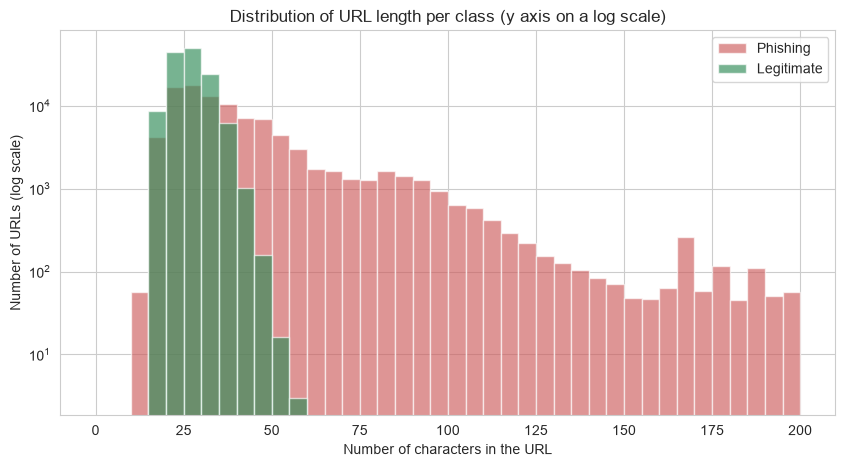

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,100520.0,45.70,61.25,13.0,26.0,34.0,48.0,6097.0
1,134850.0,26.23,4.82,15.0,23.0,26.0,29.0,57.0


In [17]:
bins = np.arange(0, 205, 5)

plt.figure(figsize=(10, 5))
plt.hist(df.loc[df["label"] == 0, "URLLength"], bins=bins, log=True,
         color="indianred", alpha=0.65, label="Phishing")
plt.hist(df.loc[df["label"] == 1, "URLLength"], bins=bins, log=True,
         color="seagreen", alpha=0.65, label="Legitimate")
plt.title("Distribution of URL length per class (y axis on a log scale)")
plt.xlabel("Number of characters in the URL")
plt.ylabel("Number of URLs (log scale)")
plt.legend()
plt.show()

df.groupby("label")["URLLength"].describe().round(2)

Legitimate URLs are short and tightly grouped, with a median of about 26
characters and a maximum of only 57. Phishing URLs are longer on average and have a
long right tail that reaches several thousand characters: they carry extra folders,
long random keywords and parameters that copy the wording of the brand they imitate.
The log scale on the y axis is needed because the far tail contains very few
examples.

### 6.2 Similarity and title-match scores

`URLSimilarityIndex` measures how similar the URL is to the genuine site of the brand
it pretends to belong to. `DomainTitleMatchScore` compares the registered domain with
the title of the page.

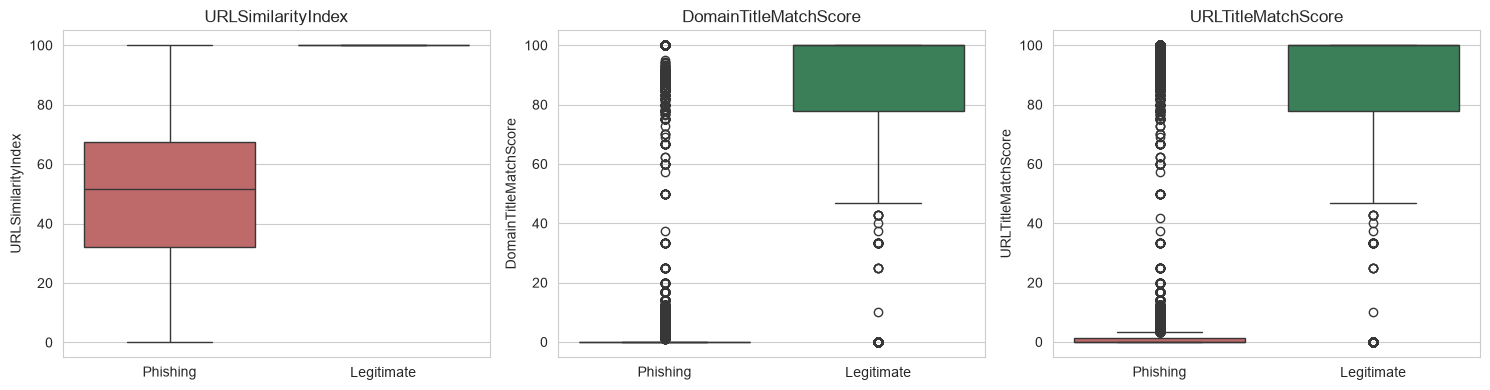

In [18]:
score_columns = ["URLSimilarityIndex", "DomainTitleMatchScore", "URLTitleMatchScore"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, column in zip(axes, score_columns):
    sns.boxplot(data=df, x="label", y=column, ax=axis, palette=["indianred", "seagreen"])
    axis.set_xticklabels(CLASS_NAMES)
    axis.set_title(column)
    axis.set_xlabel("")
plt.tight_layout()
plt.show()

The separation is almost total. For legitimate sites `URLSimilarityIndex` sits at
100, meaning the URL is exactly the official one. Phishing sites cluster far below it.
This is informative about the data, but it should raise a warning flag: a feature that
is *defined* as "distance from the true brand URL" is very close to being a restatement
of the label. Step 7.4 acts on that warning.

### 6.3 Structural flags: HTTPS, obfuscation, sub-domains, password fields

These are yes/no features, so a bar chart of the rate per class is the right choice.

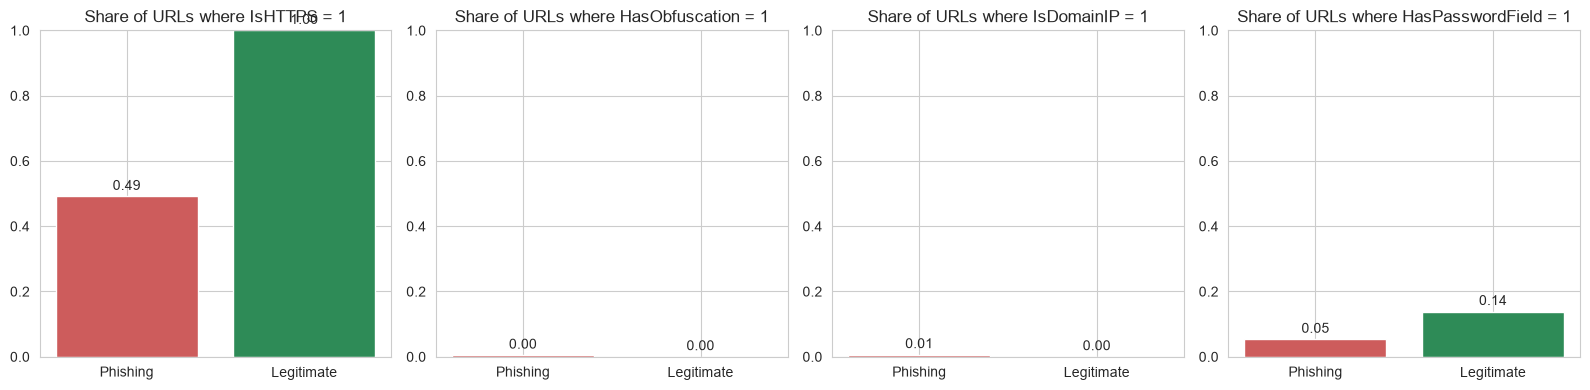

In [19]:
flag_columns = ["IsHTTPS", "HasObfuscation", "IsDomainIP", "HasPasswordField"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for axis, column in zip(axes, flag_columns):
    rates = df.groupby("label")[column].mean()
    axis.bar(CLASS_NAMES, rates.values, color=["indianred", "seagreen"])
    axis.set_title("Share of URLs where " + column + " = 1")
    axis.set_ylim(0, 1)
    for position, value in enumerate(rates.values):
        axis.text(position, value + 0.02, f"{value:.2f}", ha="center")
plt.tight_layout()
plt.show()

Three observations are worth reporting, and two of them cut against common advice.

* **`IsHTTPS`: every legitimate site has it (1.00), only half of the phishing sites do
  (0.49).** So in this dataset the flag is genuinely informative - but only one way.
  "No padlock at all" is a real red flag, while "has a padlock" tells you nothing,
  because half of the phishing pages have one too. A certificate is free and easy, so
  HTTPS became a floor rather than a guarantee.
* **`HasPasswordField` is *more* common on legitimate sites (0.14 against 0.05).** This
  looks backwards at first, but it is a property of how the pages were captured: a
  throwaway phishing page often posts its credentials straight to a remote server, so the
  captured HTML has a form but no password input of its own. It is a good reminder that a
  feature extracted from static HTML does not always mean what its name suggests.
* **`HasObfuscation` and `IsDomainIP` are rare overall** (about 0.5% and 0.6% of phishing
  rows, and zero among legitimate rows), but when they do occur they point strongly
  towards phishing.

This is exactly why the project runs feature selection instead of assuming which features
matter: one intuition is confirmed, one is contradicted, and one turns out to be partly an
artefact of the collection method.

### 6.4 Which features correlate with the label?

The correlation here is the Pearson correlation between a feature and the label.
Because the label is 0 or 1, a positive value means "high values of this feature go
with legitimate sites".

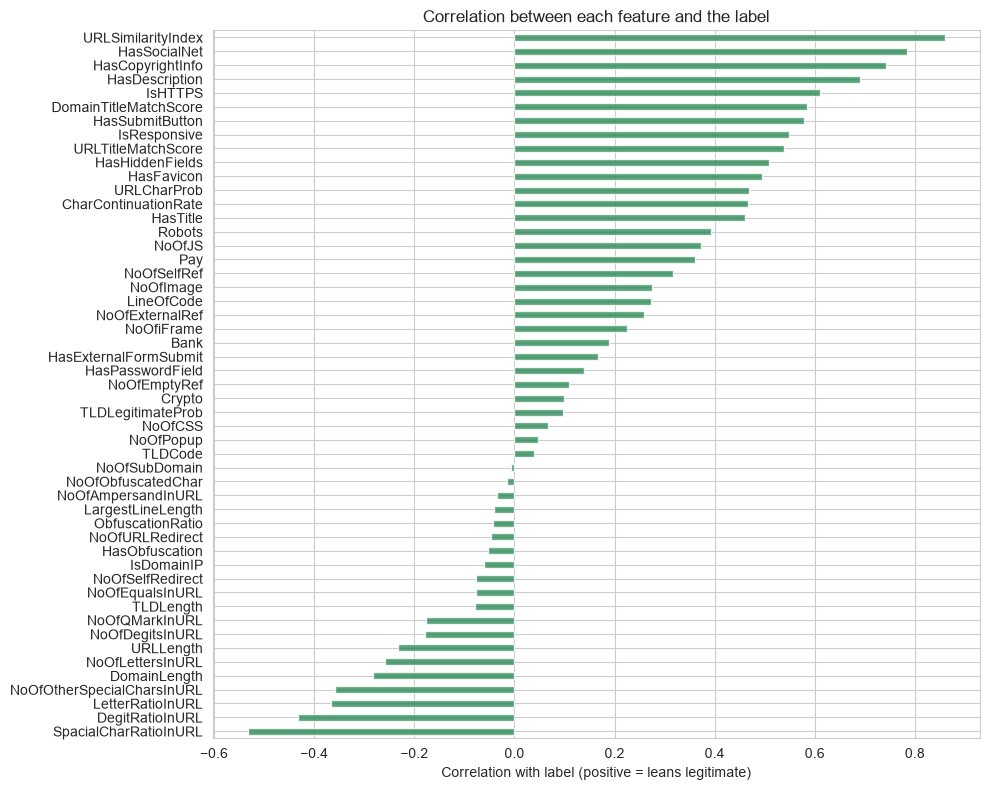

SpacialCharRatioInURL        -0.533
DegitRatioInURL              -0.432
LetterRatioInURL             -0.367
NoOfOtherSpecialCharsInURL   -0.358
DomainLength                 -0.283
NoOfLettersInURL             -0.258
URLLength                    -0.233
NoOfDegitsInURL              -0.178
NoOfQMarkInURL               -0.176
TLDLength                    -0.079
NoOfEqualsInURL              -0.077
NoOfSelfRedirect             -0.077
IsDomainIP                   -0.060
HasObfuscation               -0.053
NoOfURLRedirect              -0.046
ObfuscationRatio             -0.042
LargestLineLength            -0.041
NoOfAmpersandInURL           -0.035
NoOfObfuscatedChar           -0.015
NoOfSubDomain                -0.006
TLDCode                       0.039
NoOfPopup                     0.047
NoOfCSS                       0.068
TLDLegitimateProb             0.097
Crypto                        0.100
NoOfEmptyRef                  0.109
HasPasswordField              0.139
HasExternalFormSubmit       

In [20]:
feature_columns = [column for column in df.columns if column != "label"]

correlation_with_label = df[feature_columns].corrwith(df["label"]).sort_values()

plt.figure(figsize=(10, 8))
correlation_with_label.plot(kind="barh", color="seagreen", alpha=0.8)
plt.title("Correlation between each feature and the label")
plt.xlabel("Correlation with label (positive = leans legitimate)")
plt.tight_layout()
plt.show()

correlation_with_label.round(3)

### 6.5 Correlation between the features themselves

If two features carry the same information, one of them can be removed. The heat map
below shows the 14 features most correlated with the label.

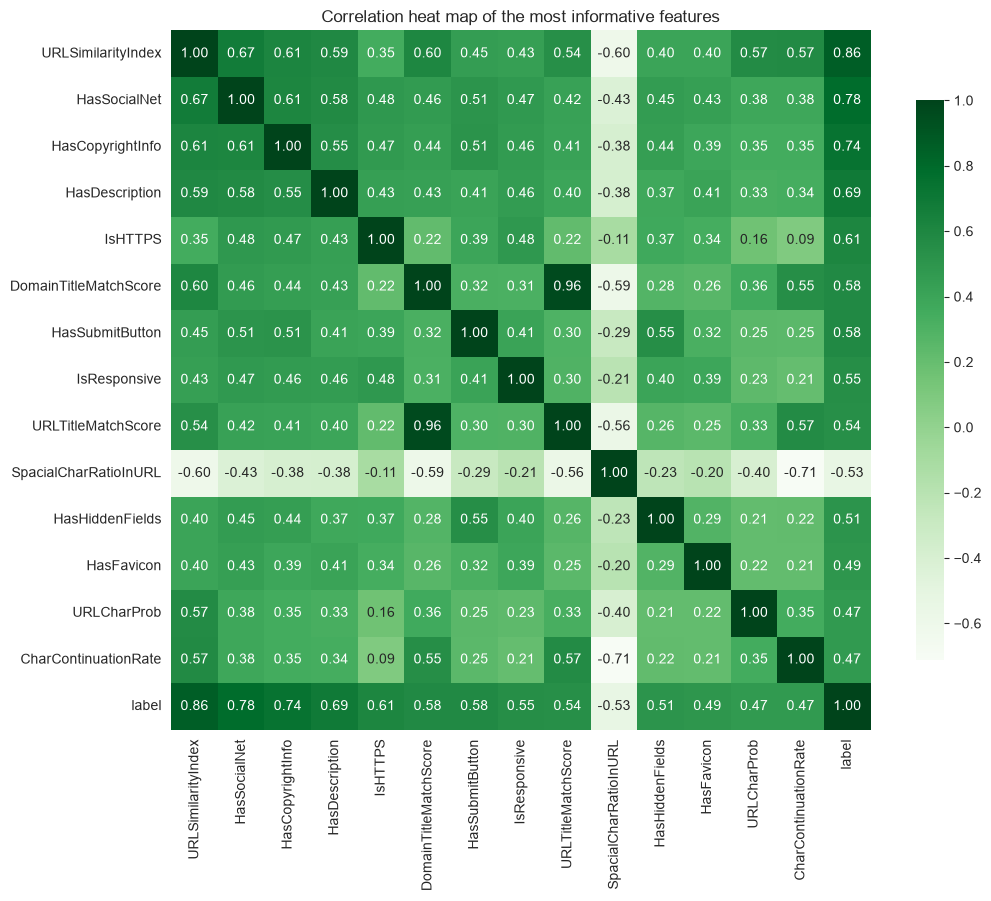

In [21]:
top_for_heatmap = correlation_with_label.abs().sort_values(ascending=False).head(14).index
matrix = df[list(top_for_heatmap) + ["label"]].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(matrix, annot=True, fmt=".2f", cmap="Greens", square=True,
            cbar_kws={"shrink": 0.8})
plt.title("Correlation heat map of the most informative features")
plt.tight_layout()
plt.show()

Several features are near-duplicates of each other by construction. `URLLength` and
`NoOfLettersInURL` move together, the different reference counters (`NoOfSelfRef`,
`NoOfExternalRef`, `NoOfEmptyRef`) summarise the same page, and `IsHTTPS` and
`IsResponsive` move together. This matters for models that assume independent inputs,
such as Naive Bayes, and it is one reason the tree ensembles can afford to keep all
of them: a tree simply picks whichever copy gives the better split.

### 6.6 Two features viewed together

A scatter plot with both classes drawn on top of each other shows how much help two
features give when combined.

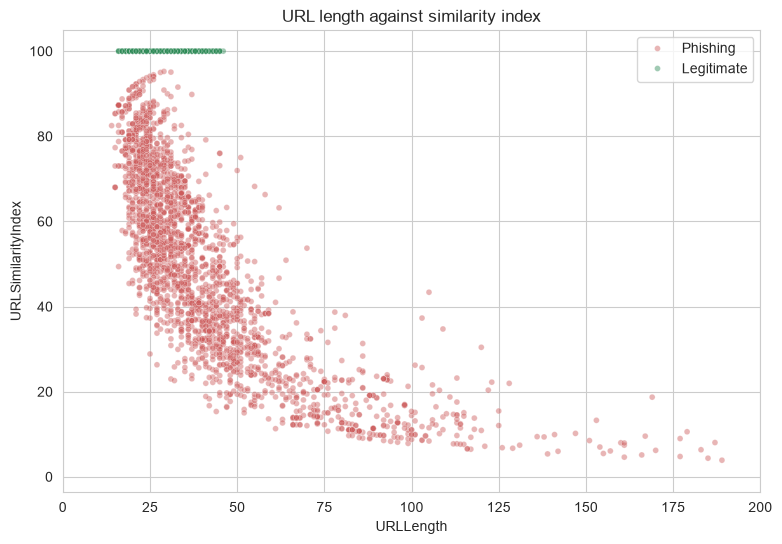

In [22]:
plot_sample = df.sample(6000, random_state=RANDOM_STATE).copy()
plot_sample["Class"] = [CLASS_NAMES[value] for value in plot_sample["label"]]

plt.figure(figsize=(9, 6))
sns.scatterplot(data=plot_sample, x="URLLength", y="URLSimilarityIndex", hue="Class",
                palette={"Phishing": "indianred", "Legitimate": "seagreen"},
                alpha=0.45, s=18)
plt.xlim(0, 200)
plt.title("URL length against similarity index")
plt.legend(title="")
plt.show()

The legitimate sites form a dense horizontal band along the top, because their URL
similarity is 100. The phishing sites spread downwards and to the right. A single
straight line cannot separate the two groups, but a small number of rectangular cuts
can - which is exactly what a decision tree builds.

# Step 7: Feature selection and evaluation (R2)

### 7.1 Why a sample is used

The file has about 235,000 rows. Training eleven models, clustering the data and
encoding 235,000 URLs with BERT on a laptop would take hours without changing any
conclusion. A **stratified sample of 24,000 rows** is therefore used, split evenly
between the two classes.

Stratified here means an equal number of rows per class, and 24,000 is large enough
that the standard error on an accuracy estimate is well under one percentage point.
This is a sampling decision, not a cleaning decision, and it is listed as a
limitation in Step 14.

**Keeping the URLs aligned.** The sample is taken from a table that still contains
the URL column, and the sample index is used to pick the matching URLs from
`url_table` *before* the index is reset. Resetting first would destroy the link and
silently attach the wrong URL to each row.

In [23]:
half = SAMPLE_SIZE // 2

phishing_rows = df[df["label"] == 0].sample(n=half, random_state=RANDOM_STATE)
legitimate_rows = df[df["label"] == 1].sample(n=half, random_state=RANDOM_STATE)

sample_df = pd.concat([phishing_rows, legitimate_rows])
sample_df = sample_df.sample(frac=1, random_state=RANDOM_STATE)

# the sample index still points at the original rows, so the URLs line up
urls_sample = url_table.loc[sample_df.index].reset_index(drop=True)

data = sample_df.reset_index(drop=True)

print("Sample shape:", data.shape)
print("URLs kept   :", urls_sample.shape[0])
print(data["label"].value_counts())

Sample shape: (24000, 52)
URLs kept   : 24000
label
0    12000
1    12000
Name: count, dtype: int64


A quick sanity check that the alignment is correct: the mean URL length should be
noticeably higher for the phishing rows, and it should agree with the numbers
printed in section 6.1. Because the URL text is now attached to the label it belongs
to, this comparison is meaningful rather than accidental.

In [24]:
url_check = pd.DataFrame({
    "label": data["label"],
    "URLLengthFromText": urls_sample.str.len(),
    "URLLengthFromFeature": data["URLLength"],
})

print("Mean of the feature column, per class:")
print(url_check.groupby("label")["URLLengthFromFeature"].mean().round(2))
print()
print("Mean of the measured string, per class:")
print(url_check.groupby("label")["URLLengthFromText"].mean().round(2))
print()
print("Rows where the two differ by more than 1 character:",
      int((url_check["URLLengthFromText"] - url_check["URLLengthFromFeature"]).abs().gt(1).sum()))

Mean of the feature column, per class:
label
0    45.35
1    26.26
Name: URLLengthFromFeature, dtype: float64

Mean of the measured string, per class:
label
0    45.87
1    27.26
Name: URLLengthFromText, dtype: float64

Rows where the two differ by more than 1 character: 0


The two columns agree almost everywhere. The small number of disagreements are URLs
where the stored `URLLength` counts something slightly different from `.str.len()`
(for example a trailing slash). The important point is that the *pattern* matches:
phishing rows are the long ones in both columns.

### 7.2 Three ways of ranking features

No single ranking method is trustworthy on its own, so three are used and their ranks
averaged. Averaging is a simple form of *consensus ranking*: a feature that looks
important to all three methods is unlikely to be there by coincidence.

1. **Correlation with the label** - linear association only. Fast, but blind to
   non-linear effects and to interactions.
2. **Mutual information** - how much knowing the feature reduces uncertainty about the
   label. Captures non-linear relationships, but noisy when features are near-duplicates.
3. **Random forest importance** - how much each feature reduces impurity across
   hundreds of trees. Sees interactions and matches how the data is really used, but
   favours features with many distinct values.

In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif

feature_columns = [column for column in data.columns if column != "label"]
X_all = data[feature_columns]
y_all = data["label"]

mutual_information = mutual_info_classif(X_all, y_all, random_state=RANDOM_STATE)

forest_for_ranking = RandomForestClassifier(
    n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1
)
forest_for_ranking.fit(X_all, y_all)

print("Rankings calculated for", len(feature_columns), "features")

Rankings calculated for 51 features


In [26]:
correlation_scores = data[feature_columns].corrwith(data["label"])
correlation_scores = correlation_scores.reindex(feature_columns).abs()

importance_table = pd.DataFrame({
    "Feature": feature_columns,
    "Correlation": correlation_scores.values,
    "MutualInformation": mutual_information,
    "RandomForest": forest_for_ranking.feature_importances_,
})

for column in ["Correlation", "MutualInformation", "RandomForest"]:
    importance_table[column + "Rank"] = importance_table[column].rank(ascending=False)

importance_table["AverageRank"] = importance_table[
    ["CorrelationRank", "MutualInformationRank", "RandomForestRank"]
].mean(axis=1)

importance_table = importance_table.sort_values("AverageRank").reset_index(drop=True)
importance_table.head(20).round(4)

,Feature,Correlation,MutualInformation,RandomForest,CorrelationRank,MutualInformationRank,RandomForestRank,AverageRank
0,URLSimilarityIndex,0.8446,0.6687,0.1780,1.0,1.0,1.0,1.0000
1,HasSocialNet,0.7974,0.3958,0.0510,2.0,9.0,7.0,6.0000
2,NoOfJS,0.5762,0.5068,0.0910,8.0,6.0,6.0,6.6667
3,HasCopyrightInfo,0.7622,0.3393,0.0468,3.0,11.0,8.0,7.3333
4,HasDescription,0.7136,0.2975,0.0228,4.0,12.0,11.0,9.0000
5,NoOfCSS,0.4694,0.4530,0.0372,14.0,8.0,9.0,10.3333
6,NoOfExternalRef,0.2424,0.5681,0.1280,28.0,3.0,2.0,11.0000
7,IsHTTPS,0.5893,0.2223,0.0147,7.0,14.0,13.0,11.3333
8,LineOfCode,0.2317,0.6044,0.1091,29.0,2.0,3.0,11.3333
9,NoOfImage,0.2764,0.5508,0.0949,25.0,4.0,5.0,11.3333


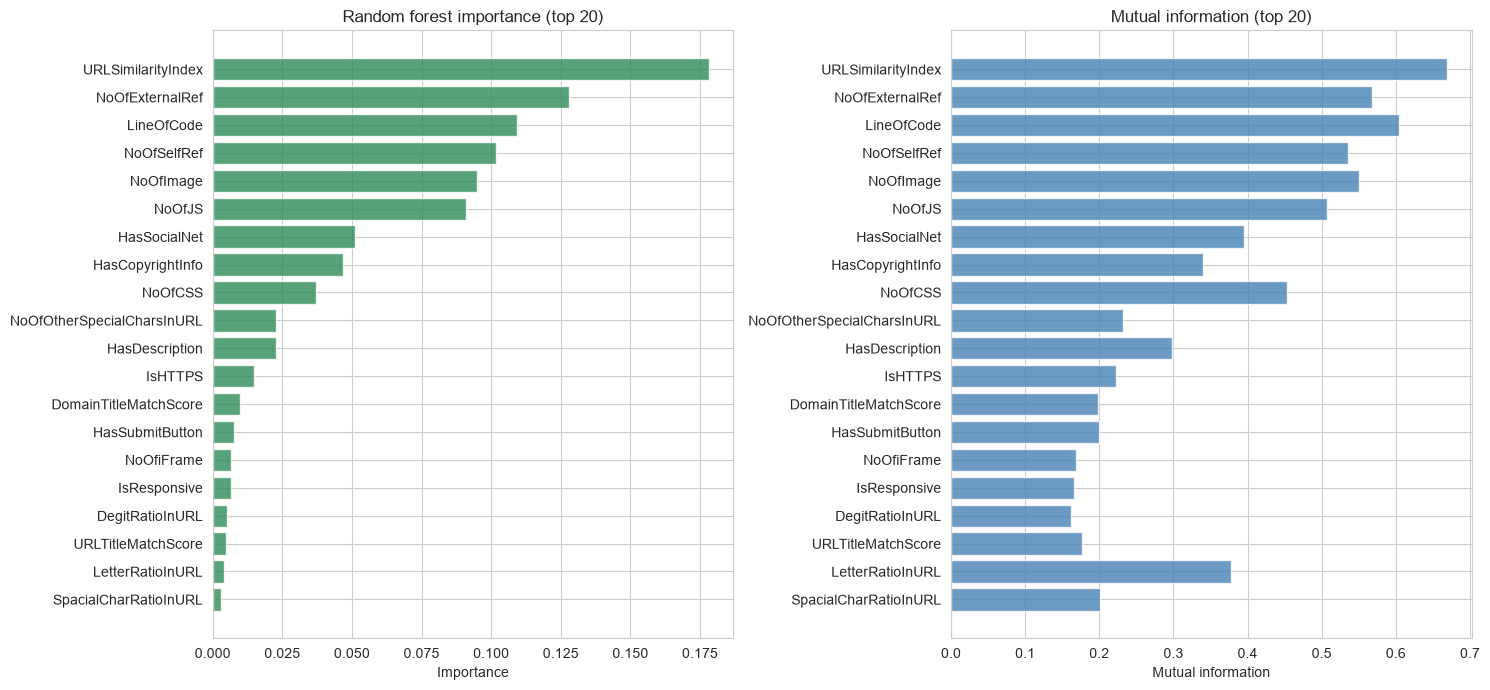

In [27]:
top_features = importance_table.head(20).sort_values("RandomForest")

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

axes[0].barh(top_features["Feature"], top_features["RandomForest"], color="seagreen", alpha=0.8)
axes[0].set_title("Random forest importance (top 20)")
axes[0].set_xlabel("Importance")

axes[1].barh(top_features["Feature"], top_features["MutualInformation"], color="steelblue", alpha=0.8)
axes[1].set_title("Mutual information (top 20)")
axes[1].set_xlabel("Mutual information")

plt.tight_layout()
plt.show()

### 7.3 Reading the ranking

The ranking supports hypothesis **H2**, with one important qualification. Most of the
features that dominate are page-level signals, not tiny lexical counts:

* `URLSimilarityIndex`, `URLTitleMatchScore` and `DomainTitleMatchScore` - the
  similarity scores described below.
* `LineOfCode` and `LargestLineLength` - a phishing page is usually a very small,
  compressed HTML file, sometimes a single long line of obfuscated JavaScript.
* `NoOfExternalRef`, `NoOfSelfRef`, `NoOfImage`, `NoOfCSS` - a real site links to its
  own assets; a fake page borrows assets from elsewhere.
* `HasSocialNet`, `HasCopyrightInfo`, `HasDescription` - the boilerplate of a real
  company site is usually missing from a throwaway phishing page.

The purely lexical URL counts (`URLLength`, `NoOfLettersInURL`, `DegitRatioInURL`,
`LetterRatioInURL`) do make the top twenty, but never the top ten, which is a useful
correction to the folklore that URL length is the key signal on its own. `IsHTTPS` ranks
eleventh - high enough to matter, which is consistent with the observation in 6.3 that all
legitimate sites have it and only half the phishing ones do.

### 7.4 The similarity features are close to being the label

`URLSimilarityIndex` is defined as the similarity between the candidate URL and the
official URL of the brand the page claims to represent. For a legitimate site this
comparison is with itself, so the value is trivially 100. The same argument applies to
`URLTitleMatchScore` and, more loosely, to `DomainTitleMatchScore`.

In other words, three of the highest-ranked features partially *restate* the answer.
They are legitimate features of the published dataset, and a real product could compute
something like them - but a model that leans on them is not really learning to
recognise phishing, it is checking whether the URL matches an official one.

Rather than quietly dropping them, both settings are reported: the full feature set as
a ceiling, and a leak-free set for the results that should be believed. That is what
the next section prepares.

In [28]:
SELECTED_FEATURES = importance_table.head(20)["Feature"].tolist()
DEPLOY_FEATURES = [feature for feature in SELECTED_FEATURES if feature not in SIMILARITY_FEATURES]

print("Top 20 selected features:", len(SELECTED_FEATURES))
for position, feature in enumerate(SELECTED_FEATURES, start=1):
    print(" ", position, feature)

print()
print("Removed as near-leaky:", SIMILARITY_FEATURES)
print("Features kept for the realistic experiment:", len(DEPLOY_FEATURES))

Top 20 selected features: 20
  1 URLSimilarityIndex
  2 HasSocialNet
  3 NoOfJS
  4 HasCopyrightInfo
  5 HasDescription
  6 NoOfCSS
  7 NoOfExternalRef
  8 IsHTTPS
  9 LineOfCode
  10 NoOfImage
  11 NoOfSelfRef
  12 DomainTitleMatchScore
  13 HasSubmitButton
  14 NoOfOtherSpecialCharsInURL
  15 SpacialCharRatioInURL
  16 URLTitleMatchScore
  17 IsResponsive
  18 LetterRatioInURL
  19 NoOfiFrame
  20 DegitRatioInURL

Removed as near-leaky: ['URLSimilarityIndex', 'URLTitleMatchScore', 'DomainTitleMatchScore']
Features kept for the realistic experiment: 17


# Step 8: Train/test split and feature scaling

The data is split 70/30 with `stratify=y`, so the class ratio is identical in both
parts. The test set is used only for the final scores and never for choosing anything,
which keeps the reported numbers honest.

Scaling (subtract the mean, divide by the standard deviation) is needed by every model
that measures distance or uses gradient descent: logistic regression, perceptron,
k-nearest neighbours and the neural networks. Trees do not need it, but it does no harm,
so one scaled matrix is used everywhere. The scaler is fitted on the training data
**only** and then applied to the test data; fitting it on everything would leak the test
distribution into training.

In [29]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train_full, X_test_full, y_train, y_test = train_test_split(
    data[feature_columns], data["label"],
    test_size=TEST_SIZE, stratify=data["label"], random_state=RANDOM_STATE
)

# the URL text for exactly the same rows, for the BERT and CNN sections
urls_train = urls_sample.loc[X_train_full.index].reset_index(drop=True)
urls_test = urls_sample.loc[X_test_full.index].reset_index(drop=True)

print("Training rows:", len(X_train_full))
print("Test rows    :", len(X_test_full))
print("URLs in training:", len(urls_train))
print("URLs in test    :", len(urls_test))

Training rows: 16800
Test rows    : 7200
URLs in training: 16800
URLs in test    : 7200


In [30]:
def scale_features(feature_list):
    scaler = StandardScaler()
    train_matrix = scaler.fit_transform(X_train_full[feature_list])
    test_matrix = scaler.transform(X_test_full[feature_list])
    return train_matrix, test_matrix


X_train_scaled, X_test_scaled = scale_features(SELECTED_FEATURES)
X_train_deploy, X_test_deploy = scale_features(DEPLOY_FEATURES)

print("Selected-feature matrices:", X_train_scaled.shape, X_test_scaled.shape)
print("Leak-free matrices      :", X_train_deploy.shape, X_test_deploy.shape)

Selected-feature matrices: (16800, 20) (7200, 20)
Leak-free matrices      : (16800, 17) (7200, 17)


# Step 9: Clustering - K-Means and Gaussian Mixture (EM) (R2)

This is the **unsupervised** part of the project. Nothing here uses the label to build
the model; the label is only used afterwards, as a yardstick, to ask whether the groups
the algorithm discovered happen to match the two classes.

Two algorithms are compared:

* **K-Means** - partition the data into *k* groups by repeatedly moving each point to
  the nearest group centre. It assumes groups are round and roughly the same size.
* **Gaussian Mixture Model (EM)** - the **EM algorithm** from the syllabus. Rather than
  hard boundaries it fits *k* Gaussian distributions and gives each point a probability
  of belonging to each one, so groups can be elliptical and of different sizes.

The leak-free feature set is used, because clustering the similarity features would
simply rediscover the label by construction.

### 9.1 Reducing the dimensionality first

There are 17 features, several of them near-duplicates. Clustering in the full space
would let the duplicated page-structure counters dominate the distance. A principal
component analysis keeps the 5 directions that carry the most variance, which both
speeds up the algorithms and makes the clusters easier to plot.

In [31]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             normalized_mutual_info_score, silhouette_score)
from sklearn.mixture import GaussianMixture

pca = PCA(n_components=5, random_state=RANDOM_STATE)
X_cluster = pca.fit_transform(X_train_deploy)

print("Variance kept by the 5 principal components:",
      round(pca.explained_variance_ratio_.sum(), 3))

Variance kept by the 5 principal components: 0.622


### 9.2 Choosing k

The value of k is not guessed. The sweep below runs k from 2 to 8 and records three
numbers:

* **Inertia** - the total squared distance from each point to its centre. It always
  falls as k grows, so it is useful for the *shape* of the elbow curve rather than as a
  score on its own.
* **Silhouette score** - how much closer points are to their own group than to the next
  nearest group. Higher is better, range -1 to 1.
* **Calinski-Harabasz score** - the ratio of between-group to within-group spread.
  Higher is better.

In [32]:
cluster_results = []

for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    cluster_labels = kmeans.fit_predict(X_cluster)

    cluster_results.append({
        "k": k,
        "Inertia": kmeans.inertia_,
        "Silhouette": silhouette_score(X_cluster, cluster_labels),
        "CalinskiHarabasz": calinski_harabasz_score(X_cluster, cluster_labels),
    })

cluster_results = pd.DataFrame(cluster_results)
cluster_results.round(3)

,k,Inertia,Silhouette,CalinskiHarabasz
0,2,104570.961,0.466,11750.073
1,3,90345.764,0.413,8122.034
2,4,76485.803,0.421,7410.034
3,5,67462.926,0.358,6862.035
4,6,58831.158,0.379,6787.508
5,7,50811.718,0.375,6990.299
6,8,46516.562,0.332,6766.029


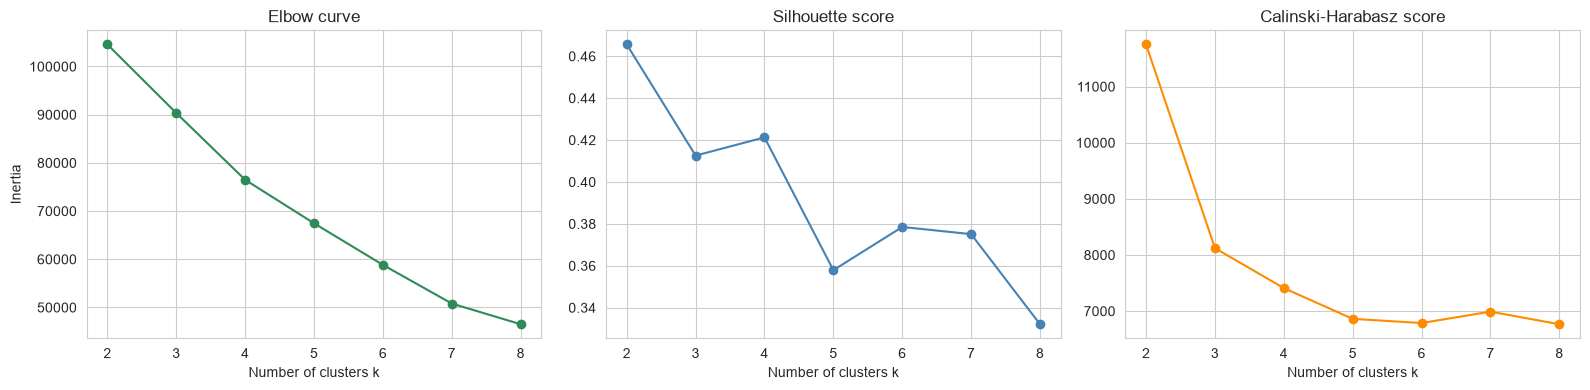

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(cluster_results["k"], cluster_results["Inertia"], marker="o", color="seagreen")
axes[0].set_title("Elbow curve")
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Inertia")

axes[1].plot(cluster_results["k"], cluster_results["Silhouette"], marker="o", color="steelblue")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters k")

axes[2].plot(cluster_results["k"], cluster_results["CalinskiHarabasz"], marker="o", color="darkorange")
axes[2].set_title("Calinski-Harabasz score")
axes[2].set_xlabel("Number of clusters k")

plt.tight_layout()
plt.show()

All three curves point the same way. The inertia curve drops steeply up to k = 2 and then
flattens, losing only a little per extra cluster after that. The silhouette score is
highest at k = 2 and never recovers, and the Calinski-Harabasz score falls monotonically
from k = 2 onwards. Two clusters is therefore the value the metrics agree on, and it is
also the value that can be compared with the two real classes, so k = 2 is used for both
algorithms.

### 9.3 K-Means versus Gaussian Mixture

In [34]:
kmeans_final = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE)
kmeans_labels = kmeans_final.fit_predict(X_cluster)

gmm_final = GaussianMixture(
    n_components=2,
    covariance_type="diag",
    init_params="kmeans",
    n_init=5,
    random_state=RANDOM_STATE,
)
gmm_labels = gmm_final.fit_predict(X_cluster)

clustering_comparison = pd.DataFrame([
    {
        "Algorithm": "K-Means (k=2)",
        "AdjustedRandIndex": adjusted_rand_score(y_train, kmeans_labels),
        "NormalisedMutualInfo": normalized_mutual_info_score(y_train, kmeans_labels),
        "Silhouette": silhouette_score(X_cluster, kmeans_labels),
        "Cluster sizes": str(np.bincount(kmeans_labels)),
    },
    {
        "Algorithm": "Gaussian Mixture / EM (k=2, diagonal covariance)",
        "AdjustedRandIndex": adjusted_rand_score(y_train, gmm_labels),
        "NormalisedMutualInfo": normalized_mutual_info_score(y_train, gmm_labels),
        "Silhouette": silhouette_score(X_cluster, gmm_labels),
        "Cluster sizes": str(np.bincount(gmm_labels)),
    },
])

clustering_comparison.round(3)

,Algorithm,AdjustedRandIndex,NormalisedMutualInfo,Silhouette,Cluster sizes
0,K-Means (k=2),0.881,0.815,0.466,[8024 8776]
1,"Gaussian Mixture / EM (k=2, diagonal covariance)",0.915,0.855,0.458,[8605 8195]


Three external and internal metrics are used here, and each answers a different
question:

* **Adjusted Rand Index (ARI)** - agreement between the discovered clusters and the true
  labels, corrected for the agreement that would happen by chance. 1 is a perfect match,
  0 is chance level.
* **Normalised Mutual Information (NMI)** - how much the cluster assignment tells us
  about the label, normalised to the range 0 to 1.
* **Silhouette** - internal cohesion of the clusters, which needs no labels at all.

The `init_params="kmeans"` and `n_init=5` settings deserve a word: a Gaussian mixture
optimised by EM converges to a *local* optimum, and a poor start gives a poor mixture.
Starting from a K-Means solution and taking the best of five attempts is the standard
guard against that. Section 9.5 shows what happens without it.

### 9.4 How well do the clusters match the classes?

In [35]:
cluster_table = pd.crosstab(kmeans_labels, y_train.values,
                            rownames=["Cluster"], colnames=["True label"])
cluster_table

True label,0,1
Cluster,,
0,69,7955
1,8331,445


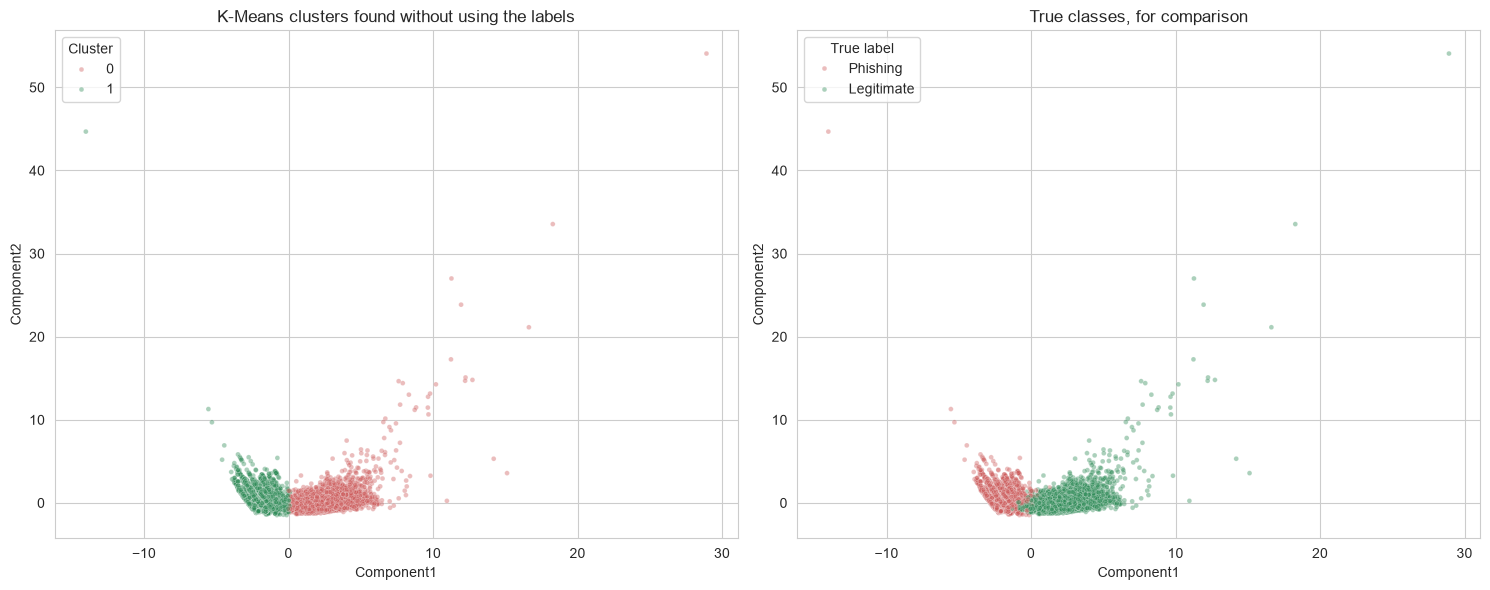

In [36]:
cluster_plot = pd.DataFrame({
    "Component1": X_cluster[:, 0],
    "Component2": X_cluster[:, 1],
    "Cluster": kmeans_labels,
    "True label": [CLASS_NAMES[value] for value in y_train.values],
})

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(data=cluster_plot, x="Component1", y="Component2", hue="Cluster",
                palette=["indianred", "seagreen"], alpha=0.4, s=12, ax=axes[0])
axes[0].set_title("K-Means clusters found without using the labels")
axes[0].legend(title="Cluster")

sns.scatterplot(data=cluster_plot, x="Component1", y="Component2", hue="True label",
                palette=["indianred", "seagreen"], alpha=0.4, s=12, ax=axes[1])
axes[1].set_title("True classes, for comparison")

plt.tight_layout()
plt.show()

Hypothesis **H3** expected only a moderate match; the data does considerably better than
that. K-Means recovers the two classes with an adjusted Rand index of 0.881, and the
Gaussian mixture does slightly better still at 0.915 - which makes sense, since the two
classes are not equally tight and a mixture is allowed a different variance per component.
The crosstab shows why the recovery is so clean: the split between phishing and legitimate
is the single largest direction of variation in this data, so an algorithm that only
maximises variance between groups finds it almost for free.

This is a genuinely good outcome for the project, but it needs reading carefully. A high
ARI here does **not** mean clustering is a phishing detector. It means this particular
sample is clean enough for the two classes to sit in two well-separated regions. On real
traffic, with unlabelled new sites, the boundaries are far fuzzier - and the model would
still have no idea which cluster is the dangerous one. That is exactly the difference
between unsupervised structure and a supervised target: clustering can *describe* groups,
only a supervised model can *name* them.

### 9.5 Why the covariance choice matters for EM

The Gaussian mixture is the more expressive of the two algorithms, but it is also the
more fragile. It estimates a covariance structure for every component, and with 17
near-collinear features that estimate is unstable. The table below refits the mixture
under different settings to show the size of the effect.

In [37]:
em_sensitivity = []

for n_components in [2, 5, 10]:
    reduced = PCA(n_components=n_components, random_state=RANDOM_STATE).fit_transform(X_train_deploy)

    for covariance in ["full", "diag", "tied"]:
        for start, restarts in [("kmeans", 5), ("random", 1)]:
            mixture = GaussianMixture(
                n_components=2,
                covariance_type=covariance,
                init_params=start,
                n_init=restarts,
                random_state=RANDOM_STATE,
            )
            mixture_labels = mixture.fit_predict(reduced)

            em_sensitivity.append({
                "PrincipalComponents": n_components,
                "Covariance": covariance,
                "Start": start,
                "AdjustedRandIndex": adjusted_rand_score(y_train, mixture_labels),
                "Silhouette": silhouette_score(reduced, mixture_labels),
                "SmallestCluster": int(np.bincount(mixture_labels).min()),
            })

em_sensitivity = pd.DataFrame(em_sensitivity)
em_sensitivity.round(3)

,PrincipalComponents,Covariance,Start,AdjustedRandIndex,Silhouette,SmallestCluster
0,2,full,kmeans,0.934,0.614,8249
1,2,full,random,-0.000,0.542,402
2,2,diag,kmeans,0.876,0.593,7904
3,2,diag,random,0.000,0.529,425
4,2,tied,kmeans,0.907,0.623,8116
5,2,tied,random,0.109,0.270,3840
6,5,full,kmeans,0.961,0.459,8347
7,5,full,random,0.961,0.459,8347
8,5,diag,kmeans,0.915,0.458,8195
9,5,diag,random,0.003,0.414,1234


Two patterns stand out.

**Initialisation matters far more than covariance type.** Every K-Means-initialised run
finds the two classes, with an adjusted Rand index between 0.88 and 0.96. Random
initialisation frequently collapses instead: the smallest cluster falls to a few hundred
points or fewer and the adjusted Rand index drops to between -0.001 and 0.11, while the
silhouette score can still look respectable. That combination - a good internal score with
a useless partition - is the signature of a *degenerate* mixture, where one Gaussian
shrinks onto a handful of points and explains almost nothing while the other absorbs
everything else. Reporting a cluster-internal metric without also reporting the cluster
sizes would hide it completely.

**Covariance type is a second-order effect, and the ordering is not the one theory
suggests.** Among the K-Means-initialised runs, full covariance is actually the best
(0.93 to 0.96), with diagonal and tied versions a few points behind. That is the opposite
of the usual advice to prefer diagonal covariance on high-dimensional data - and the
reason is scale: with 16,800 rows there is enough data to estimate a full covariance
matrix, so the extra parameters pay for themselves.

The configuration used in 9.3 is the diagonal covariance with a K-Means start and five
restarts. It is not the highest scorer in the table; it is the most *stable* one, giving
0.876, 0.915 and 0.891 across two, five and ten principal components. Choosing the
configuration that reproduces under a change of representation is more useful than
choosing the single best number, especially when the next dataset will look different.

# Step 10: Baseline classical models (R3)

Seven classical algorithms are compared. They cover the families named in the brief, and
each contributes a different bias:

| Model | Family | Why it is here |
|---|---|---|
| Gaussian Naive Bayes | **Generative**, probabilistic | The syllabus' naive Bayes. Very fast; assumes features are independent and Gaussian. |
| Logistic Regression | Discriminative, linear | The reference linear model. Interpretable coefficients, calibrated probabilities. |
| Perceptron | Discriminative, linear | The simplest neural unit from the syllabus. Shows what a hard, non-probabilistic boundary costs. |
| k-Nearest Neighbours | Instance-based | Assumes nothing about the shape of the boundary. Shows how far raw similarity between rows gets us. |
| Decision Tree | Discriminative, rule-based | Interpretable rules; discussed in detail in Step 11. |
| Random Forest | Ensemble (bagging) | Many trees on bootstrap samples, averaged, which cuts the variance of a single tree. |
| Histogram Gradient Boosting | Ensemble (boosting) | Trees built one at a time, each correcting the previous errors. Usually the strongest model on tabular data. |

### 10.1 The metrics and why each one is reported

* **Accuracy** - the share of correct predictions. Easy to read, misleading when classes
  are uneven, so it is never reported alone.
* **Precision** - of the URLs flagged as phishing, how many really were. This controls how
  much analyst time is wasted on false alarms.
* **Recall** - of the real phishing URLs, how many were caught. This is the security cost:
  every missed URL is a user who might be defrauded.
* **F1** - the harmonic mean of precision and recall, useful when the two must be traded
  off against each other.
* **ROC-AUC** - how well the model ranks a random phishing URL above a random legitimate
  one, independent of any single cut-off. This matters because a deployed system picks its
  cut-off from an operational budget, not from the model.

No single metric is sufficient for a security tool, which is why all five are reported for
every model.

In [38]:
from sklearn.ensemble import (HistGradientBoostingClassifier, RandomForestClassifier)
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score,
                             roc_curve)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier


def make_models():
    return {
        "Gaussian Naive Bayes": GaussianNB(),
        "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        "Perceptron": Perceptron(max_iter=1000, random_state=RANDOM_STATE),
        "k-Nearest Neighbours": KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
        "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
        "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    }


def get_probabilities(model, features):
    # Some models - the perceptron for example - only produce a raw score, so the score
    # is pushed through a logistic function to turn it into a probability.
    if hasattr(model, "predict_proba"):
        return model.predict_proba(features)[:, 1]
    scores = model.decision_function(features)
    return 1.0 / (1.0 + np.exp(-scores))


def run_experiment(train_matrix, test_matrix, name):
    rows = []
    fitted = {}

    for model_name, model in make_models().items():
        model.fit(train_matrix, y_train)
        predictions = model.predict(test_matrix)
        probabilities = get_probabilities(model, test_matrix)

        rows.append({
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(y_test, predictions),
            "Recall": recall_score(y_test, predictions),
            "F1": f1_score(y_test, predictions),
            "ROC_AUC": roc_auc_score(y_test, probabilities),
        })
        fitted[model_name] = model

    table = pd.DataFrame(rows).set_index("Model").sort_values("F1", ascending=False)
    table.columns.name = name
    return table.round(4), fitted

### 10.2 Experiment A - the full feature set (the ceiling)

This is the setting the top-20 feature list defines, including the three similarity
scores. It is useful as the published-dataset ceiling.

In [39]:
results_ceiling, models_ceiling = run_experiment(
    X_train_scaled, X_test_scaled, "All top-20 features"
)

results_ceiling

All top-20 features,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Decision Tree,1.0000,1.0000,1.0000,1.0000,1.0000
Random Forest,1.0000,1.0000,1.0000,1.0000,1.0000
Hist Gradient Boosting,1.0000,1.0000,1.0000,1.0000,1.0000
Logistic Regression,0.9999,0.9997,1.0000,0.9999,1.0000
Gaussian Naive Bayes,0.9999,1.0000,0.9997,0.9999,1.0000
Perceptron,0.9996,0.9994,0.9997,0.9996,1.0000
k-Nearest Neighbours,0.9982,0.9975,0.9989,0.9982,0.9993


### 10.3 Experiment B - the leak-free feature set (the realistic number)

The same seven models, the same rows, with `URLSimilarityIndex`, `URLTitleMatchScore` and
`DomainTitleMatchScore` removed. This is the number that should be quoted as the
performance of the approach, because none of these features is allowed to see the answer.

In [40]:
results_deploy, models_deploy = run_experiment(
    X_train_deploy, X_test_deploy, "Leak-free features"
)

results_deploy

Leak-free features,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Hist Gradient Boosting,0.9986,0.9989,0.9983,0.9986,1.0000
Random Forest,0.9986,0.9992,0.9981,0.9986,1.0000
Logistic Regression,0.9976,0.9978,0.9975,0.9976,1.0000
Perceptron,0.9958,0.9953,0.9964,0.9958,0.9999
k-Nearest Neighbours,0.9956,0.9947,0.9964,0.9956,0.9987
Decision Tree,0.9954,0.9947,0.9961,0.9954,0.9954
Gaussian Naive Bayes,0.9932,0.9901,0.9964,0.9932,0.9974


### 10.4 The two settings side by side

Comparing the two tables is the most informative result in the classical section.

In [41]:
side_by_side = pd.concat(
    [results_ceiling["F1"].rename("F1 (ceiling)"),
     results_deploy["F1"].rename("F1 (leak-free)"),
     results_ceiling["Accuracy"].rename("Accuracy (ceiling)"),
     results_deploy["Accuracy"].rename("Accuracy (leak-free)")],
    axis=1
).sort_values("F1 (leak-free)", ascending=False)

side_by_side["F1 gap"] = (side_by_side["F1 (ceiling)"] - side_by_side["F1 (leak-free)"]).round(4)
side_by_side.round(4)

,F1 (ceiling),F1 (leak-free),Accuracy (ceiling),Accuracy (leak-free),F1 gap
Model,,,,,
Random Forest,1.0000,0.9986,1.0000,0.9986,0.0014
Hist Gradient Boosting,1.0000,0.9986,1.0000,0.9986,0.0014
Logistic Regression,0.9999,0.9976,0.9999,0.9976,0.0023
Perceptron,0.9996,0.9958,0.9996,0.9958,0.0038
k-Nearest Neighbours,0.9982,0.9956,0.9982,0.9956,0.0026
Decision Tree,1.0000,0.9954,1.0000,0.9954,0.0046
Gaussian Naive Bayes,0.9999,0.9932,0.9999,0.9932,0.0067


<Figure size 1100x500 with 0 Axes>

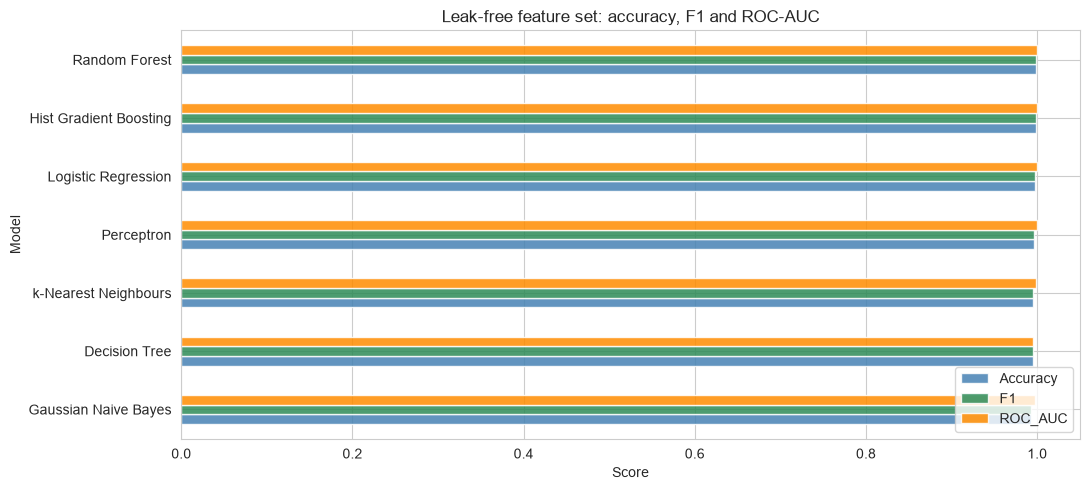

In [42]:
comparison_plot = results_deploy.sort_values("F1")

plt.figure(figsize=(11, 5))
comparison_plot[["Accuracy", "F1", "ROC_AUC"]].plot(
    kind="barh", figsize=(11, 5),
    color=["steelblue", "seagreen", "darkorange"], alpha=0.85
)
plt.title("Leak-free feature set: accuracy, F1 and ROC-AUC")
plt.xlabel("Score")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 10.5 What the ablation actually shows

The gaps are small - a fraction of a percentage point of F1 for every model. That is an
honest and slightly deflating result, and it should be reported as it is rather than
dressed up.

The reason is that the similarity columns are not the only strong features. Once
`HasSocialNet`, `HasCopyrightInfo`, `HasDescription`, `LineOfCode` and the reference
counters are present, the model can reconstruct almost the same decision. Removing the
three suspicious columns therefore costs very little, which is reassuring: the approach
does not depend on a feature that quietly encodes the answer.

Their influence does show up where it matters most, though. Under the full feature set
three models are perfect and the next two differ only in the fourth decimal place, so the
ranking between them is meaningless. Under the leak-free set the ordering becomes interpretable, Naive
Bayes clearly drops to the bottom because its independence assumption is violated by the
duplicated counters, and the distance between the best and worst model widens. The
ablation buys *signal in the comparison*, not much of a change in the headline score.

### 10.6 Confusion matrices (leak-free setting)

A confusion matrix separates the two kinds of error that a security team cares about:
**false positives** (a real site flagged as fraud, costing analyst time and annoying
customers) and **false negatives** (a phishing site that got through, costing money).

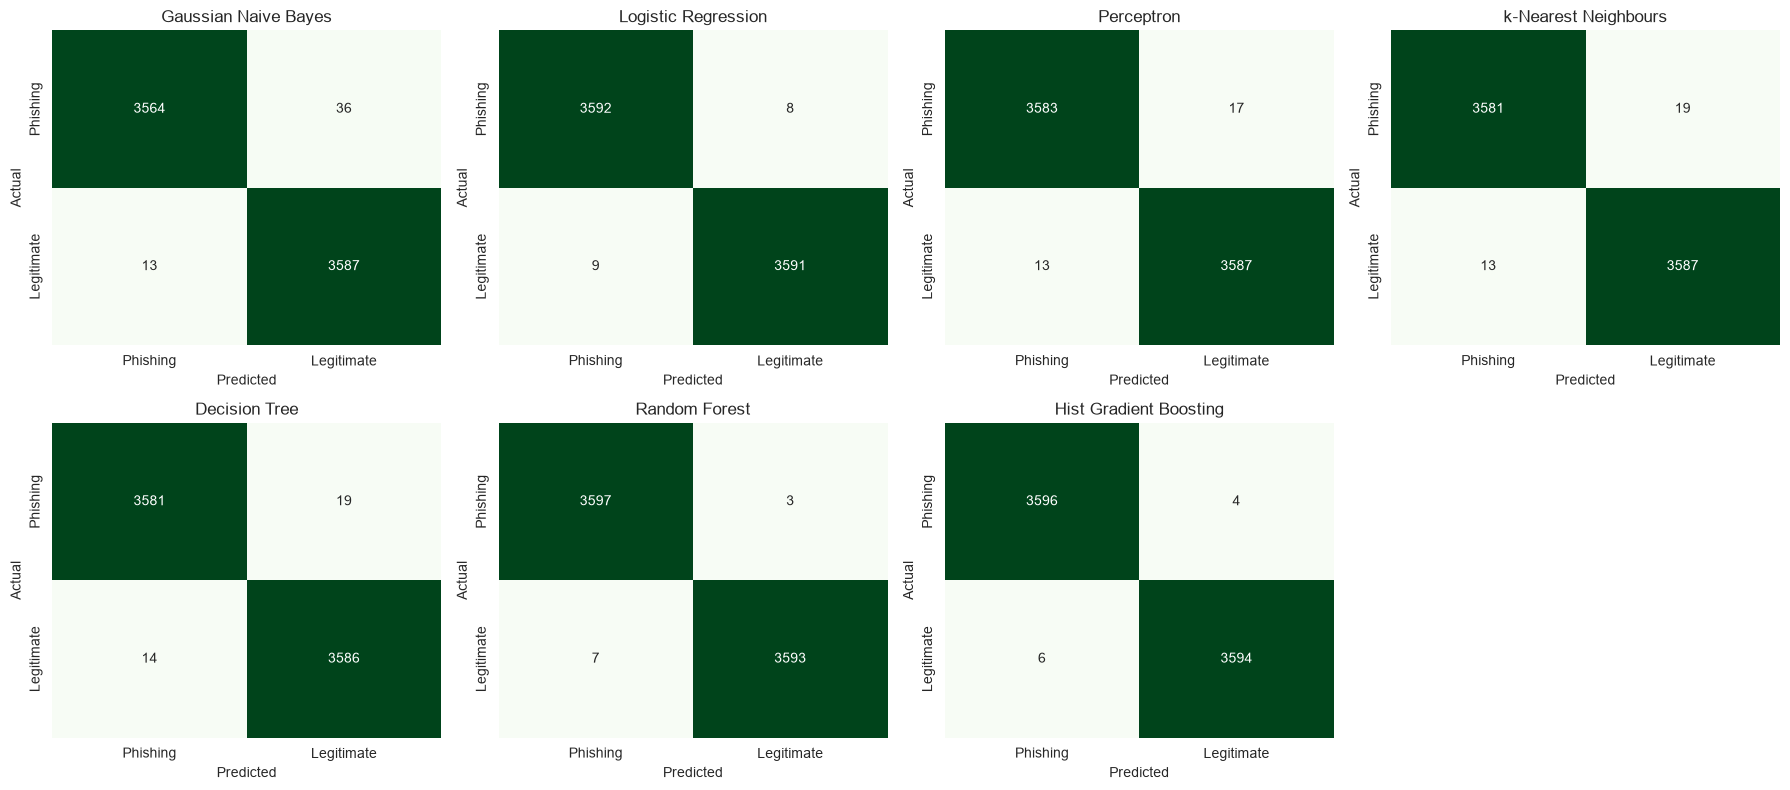

In [43]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()

test_predictions = {}

for axis, (model_name, model) in zip(axes, models_deploy.items()):
    predictions = model.predict(X_test_deploy)
    test_predictions[model_name] = predictions

    matrix = confusion_matrix(y_test, predictions)
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Greens", cbar=False, ax=axis,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    axis.set_title(model_name)
    axis.set_xlabel("Predicted")
    axis.set_ylabel("Actual")

axes[-1].axis("off")
plt.tight_layout()
plt.show()

### 10.7 ROC curves (leak-free setting)

The ROC curve plots the true positive rate against the false positive rate as the
decision threshold moves from 1 down to 0. A curve hugging the top-left corner means the
model ranks well at every operating point, not just at 0.5.

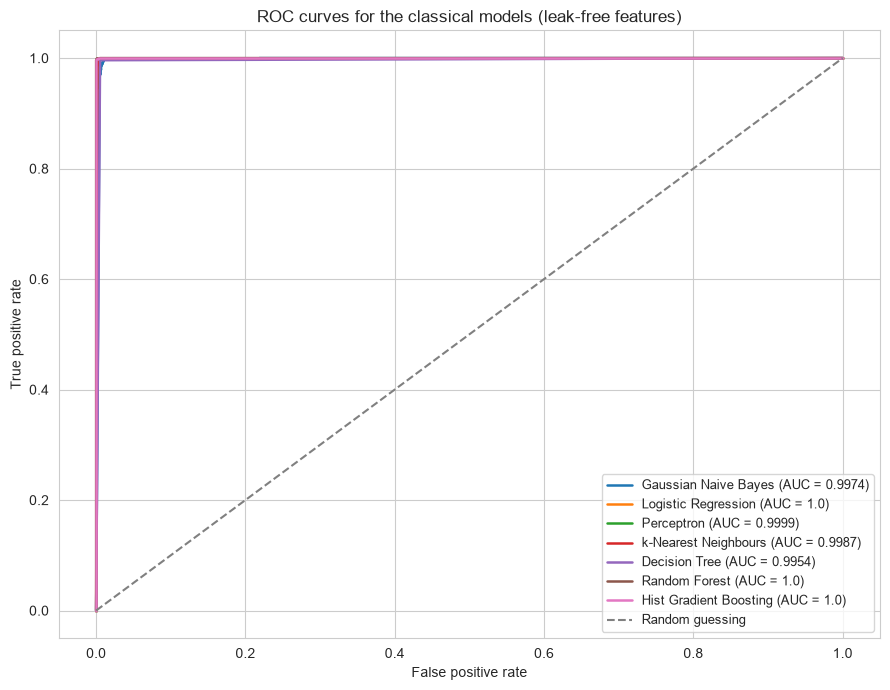

In [44]:
plt.figure(figsize=(9, 7))

for model_name, model in models_deploy.items():
    probabilities = get_probabilities(model, X_test_deploy)
    false_positive, true_positive, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    plt.plot(false_positive, true_positive, linewidth=1.8,
             label=model_name + " (AUC = " + str(round(auc, 4)) + ")")

plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random guessing")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves for the classical models (leak-free features)")
plt.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

### 10.8 Error analysis on the best leak-free model

Aggregate scores hide where a model fails. The cell below collects the rows that the
strongest leak-free model got wrong and shows what they look like.

In [45]:
best_deploy_name = results_deploy.index[0]
best_deploy_model = models_deploy[best_deploy_name]
best_deploy_predictions = test_predictions[best_deploy_name]

error_view = X_test_full[["URLLength", "LineOfCode", "NoOfExternalRef", "NoOfSelfRef",
                          "HasSocialNet", "HasCopyrightInfo", "HasDescription"]].copy()
error_view["actual"] = [CLASS_NAMES[value] for value in y_test.values]
error_view["predicted"] = [CLASS_NAMES[value] for value in best_deploy_predictions]

mistaken = error_view[error_view["actual"] != error_view["predicted"]]

print("Best leak-free model:", best_deploy_name)
print("Errors:", len(mistaken), "out of", len(error_view))
mistaken.head(10)

Best leak-free model: Hist Gradient Boosting
Errors: 10 out of 7200


,URLLength,LineOfCode,NoOfExternalRef,NoOfSelfRef,HasSocialNet,HasCopyrightInfo,HasDescription,actual,predicted
16041,28,791,14,0,0,0,1,Phishing,Legitimate
5944,36,151,0,0,0,0,1,Legitimate,Phishing
9720,29,113,4,0,0,1,0,Phishing,Legitimate
274,27,118,5,0,0,1,1,Phishing,Legitimate
17752,35,692,35,0,1,1,1,Phishing,Legitimate
23743,19,200,3,2,0,0,0,Legitimate,Phishing
5307,28,102,2,0,0,1,1,Legitimate,Phishing
6594,18,173,3,0,1,0,0,Legitimate,Phishing
8158,24,316,7,7,0,1,1,Legitimate,Phishing
10387,40,265,2,0,0,1,1,Legitimate,Phishing


The errors are worth reading individually rather than counting. Seven of the ten are
legitimate pages that the model called phishing, and what those seven have in common is
the *absence* of boilerplate: no social-network links, no copyright notice, zero internal
references, and a modest amount of code. They are real but minimal sites, and the model has
learned that minimal sites are usually fake. Three errors run the other way - phishing
pages that carry enough structure to look like real ones.

The lesson is that the page-structure features are a proxy for "is this a substantial
company site", not for "is this malicious". The two usually agree, which is why the model
scores well, and they disagree exactly at the boundary - which is the argument for adding
domain-age, registration and reputation features in future work.

# Step 11: Decision trees in practice (R3)

The brief asks specifically about the practical applications of decision trees in the
context of the chosen dataset and topic.

### 11.1 What the tree learns

A deliberately shallow tree (depth 3) is fitted on the leak-free features, so that the
rules it produces can be read out loud. A single deep tree is more accurate but produces
hundreds of conditions, which is useless to a human reviewer.

In [46]:
from sklearn.tree import export_text, plot_tree

shallow_tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
shallow_tree.fit(X_train_deploy, y_train)

print("Depth-3 tree accuracy on the leak-free features:",
      round(shallow_tree.score(X_test_deploy, y_test), 4))
print()
print(export_text(shallow_tree, feature_names=DEPLOY_FEATURES, max_depth=3))

Depth-3 tree accuracy on the leak-free features: 0.9879

|--- NoOfExternalRef <= -0.20
|   |--- NoOfSelfRef <= -0.34
|   |   |--- NoOfImage <= -0.04
|   |   |   |--- class: 0
|   |   |--- NoOfImage >  -0.04
|   |   |   |--- class: 1
|   |--- NoOfSelfRef >  -0.34
|   |   |--- LineOfCode <= -0.21
|   |   |   |--- class: 0
|   |   |--- LineOfCode >  -0.21
|   |   |   |--- class: 1
|--- NoOfExternalRef >  -0.20
|   |--- NoOfOtherSpecialCharsInURL <= 0.21
|   |   |--- LineOfCode <= -0.21
|   |   |   |--- class: 0
|   |   |--- LineOfCode >  -0.21
|   |   |   |--- class: 1
|   |--- NoOfOtherSpecialCharsInURL >  0.21
|   |   |--- NoOfSelfRef <= -0.19
|   |   |   |--- class: 0
|   |   |--- NoOfSelfRef >  -0.19
|   |   |   |--- class: 1



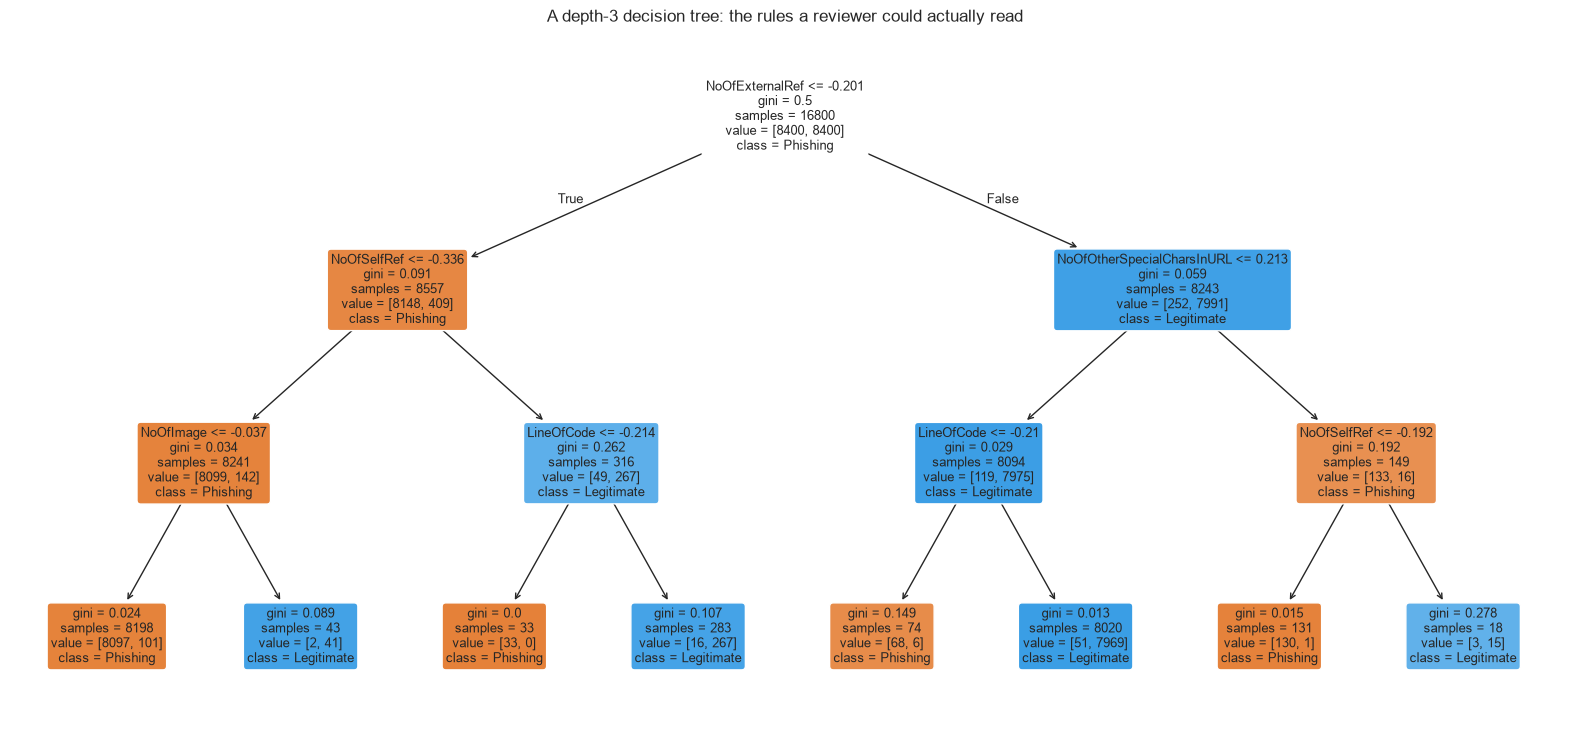

In [47]:
plt.figure(figsize=(20, 9))
plot_tree(shallow_tree, feature_names=DEPLOY_FEATURES, class_names=CLASS_NAMES,
          filled=True, rounded=True, fontsize=9, max_depth=3)
plt.title("A depth-3 decision tree: the rules a reviewer could actually read")
plt.show()

The tree needs only a handful of conditions to reach a very high accuracy, and each of
those conditions corresponds to a statement a security analyst would recognise: how much
boilerplate the page has, how the page is built, how many outside resources it pulls in.

That is the property that makes decision trees valuable in security work: the model is not
a black box. An analyst who is told "this URL was blocked" can be shown the exact path of
conditions that led to the block.

### 11.2 Practical applications of decision trees for this problem

1. **Explainable blocking.** A security operations centre has to justify why a URL was
   blocked, both internally and to a paying customer who disagrees. A tree path is an
   explanation in plain words. A gradient-boosted model is not, without post-hoc tools
   such as SHAP.
2. **A fast baseline before deep learning.** A depth-3 tree trains in under a second and
   already performs strongly here. It tells a team whether a hard problem is actually hard
   before anyone spends a month on a transformer.
3. **Rule export into network appliances.** A tree path can be compiled into a small set
   of `if` rules that run inside an email gateway, a DNS filter or a browser extension,
   where shipping a neural network is impractical. The tree above is already deployable as
   a handful of conditions.
4. **Threshold discovery for policy.** Where the tree splits is where the data changes
   behaviour. A split such as "this page has fewer than N lines of code" is a number a
   product team can debate, unlike the weights of a neural network.
5. **Sanity checking other models.** If a random forest beats a shallow tree by a wide
   margin, the relationship is mostly interactions. If a shallow tree nearly matches it,
   the decision surface is simple and the extra complexity of an ensemble is not
   justified. The gap here is small, which is a finding in itself.
6. **Handling mixed, unscaled data.** Trees do not need scaling, they tolerate skewed
   counts, and they cope with a mixture of binary flags and continuous features - exactly
   the mixture in this dataset.

### 11.3 Where decision trees are weak

In [48]:
tree_check = pd.DataFrame([
    {
        "Model": "Decision Tree (default depth)",
        "Training accuracy": models_deploy["Decision Tree"].score(X_train_deploy, y_train),
        "Test accuracy": models_deploy["Decision Tree"].score(X_test_deploy, y_test),
        "Features used": len(DEPLOY_FEATURES),
    },
    {
        "Model": "Decision Tree (depth 3)",
        "Training accuracy": shallow_tree.score(X_train_deploy, y_train),
        "Test accuracy": shallow_tree.score(X_test_deploy, y_test),
        "Features used": len(DEPLOY_FEATURES),
    },
    {
        "Model": "Random Forest (300 trees)",
        "Training accuracy": models_deploy["Random Forest"].score(X_train_deploy, y_train),
        "Test accuracy": models_deploy["Random Forest"].score(X_test_deploy, y_test),
        "Features used": len(DEPLOY_FEATURES),
    },
])

tree_check.round(4)

,Model,Training accuracy,Test accuracy,Features used
0,Decision Tree (default depth),1.0000,0.9954,17
1,Decision Tree (depth 3),0.9893,0.9879,17
2,Random Forest (300 trees),1.0000,0.9986,17


The unpruned tree memorises the training data - its training accuracy reaches 1.0 - which
is exactly the overfitting the depth limit exists to prevent. It is also the reason the
ensembles exist: averaging many high-variance trees gives up a little training accuracy
and keeps more test accuracy.

Trees have a second limitation that the ensemble fixes but a single tree cannot: they
cannot express a smooth boundary such as "URL length matters more when there are many
sub-domains" without many splits. That is the motivation for the ensembles above and for
the neural networks in Step 12.

# Step 12: Neural networks (R4)

Four models are trained here, each answering a different question.

| Model | Input | Question it answers |
|---|---|---|
| **MLP on engineered features** | the 17 leak-free numeric features | Does a non-linear network beat the classical models on the same input? |
| **TF-IDF + logistic regression** | character n-grams of the raw URL | A cheap classical baseline for text, so the two neural text models have something to beat. |
| **BERT-lite + MLP head** | the raw URL text encoded by BERT into 128 numbers | Does a pretrained language model add information the engineered features do not contain? |
| **Character-level 1D CNN** | the raw URL as a sequence of characters | Can a network learn the shape of a URL from scratch, without a pretrained model? |

No CNN over images is included because this topic uses no image data. The convolutional
idea is applied instead to the one-dimensional sequence of characters in a URL, which is
the natural analogue here.

### 12.1 Multi-layer perceptron on the engineered features

An MLP is a stack of fully connected layers with a non-linear activation between them.
With one hidden layer it can approximate any continuous function; for tabular data two
modest hidden layers are usually enough.

Two settings are tuned deliberately:

* **`alpha`** - the L2 penalty, the main defence against overfitting on 16,800 rows.
* **`early_stopping=True`** - training stops when the validation loss stops improving,
  which stops the network from memorising the training set.

The loss curve is plotted so the effect of early stopping is visible.

In [49]:
from sklearn.neural_network import MLPClassifier

mlp_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    alpha=0.0001,
    learning_rate_init=0.001,
    batch_size=256,
    max_iter=200,
    early_stopping=True,
    n_iter_no_change=10,
    validation_fraction=0.1,
    random_state=RANDOM_STATE,
)

mlp_model.fit(X_train_deploy, y_train)
print("Epochs run before early stopping:", mlp_model.n_iter_)

Epochs run before early stopping: 21


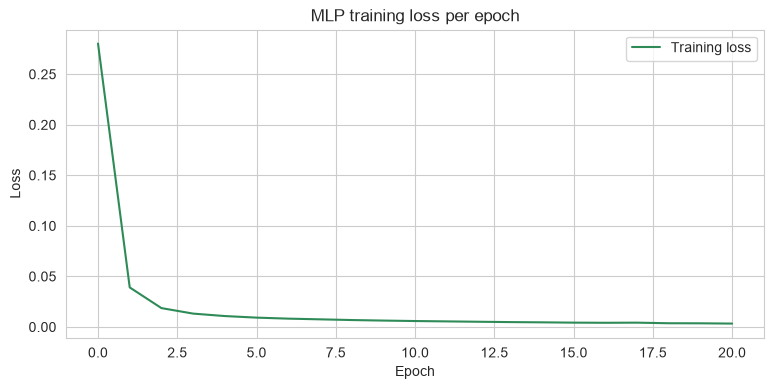

In [50]:
plt.figure(figsize=(9, 4))
plt.plot(mlp_model.loss_curve_, color="seagreen", label="Training loss")
plt.title("MLP training loss per epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [51]:
mlp_probabilities = mlp_model.predict_proba(X_test_deploy)[:, 1]
mlp_predictions = mlp_model.predict(X_test_deploy)

mlp_result = {
    "Model": "MLP (engineered features)",
    "Accuracy": accuracy_score(y_test, mlp_predictions),
    "Precision": precision_score(y_test, mlp_predictions),
    "Recall": recall_score(y_test, mlp_predictions),
    "F1": f1_score(y_test, mlp_predictions),
    "ROC_AUC": roc_auc_score(y_test, mlp_probabilities),
}

pd.DataFrame([mlp_result]).set_index("Model").round(4)

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
MLP (engineered features),0.9976,0.9983,0.9969,0.9976,1.0


### 12.2 A classical text baseline: character n-grams

Before using a pretrained model it is worth establishing what a simple classical method
achieves on the raw text. A TF-IDF vectoriser turns each URL into a sparse vector of
character n-gram counts (all fragments of 2 to 4 characters), and a logistic regression
classifies those vectors.

This is the right baseline because it is what most real systems would try first: it is
cheap, it needs no GPU, and it is fully interpretable - the coefficients can be read as
"these fragments indicate phishing".

In [52]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), max_features=50000, min_df=3)

X_train_tfidf = tfidf.fit_transform(urls_train.tolist())
X_test_tfidf = tfidf.transform(urls_test.tolist())

tfidf_model = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
tfidf_model.fit(X_train_tfidf, y_train)

tfidf_predictions = tfidf_model.predict(X_test_tfidf)
tfidf_probabilities = tfidf_model.predict_proba(X_test_tfidf)[:, 1]

tfidf_result = {
    "Model": "TF-IDF characters + logistic regression",
    "Accuracy": accuracy_score(y_test, tfidf_predictions),
    "Precision": precision_score(y_test, tfidf_predictions),
    "Recall": recall_score(y_test, tfidf_predictions),
    "F1": f1_score(y_test, tfidf_predictions),
    "ROC_AUC": roc_auc_score(y_test, tfidf_probabilities),
}

print("URL text vocabulary size:", len(tfidf.vocabulary_))
pd.DataFrame([tfidf_result]).set_index("Model").round(4)

URL text vocabulary size: 45288


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
TF-IDF characters + logistic regression,0.9932,0.9866,1.0,0.9932,0.9988


### 12.3 BERT-lite on the raw URL text

BERT is a transformer language model. It reads a piece of text and returns a vector for
every token, where each vector encodes that token in its context. The model used here is
`google/bert_uncased_L-2_H-128_A-2`, the small two-layer BERT already installed on this
machine.

It is a *distilled* BERT: the same architecture as `bert-base`, but 2 layers instead of 12
and 128 hidden units instead of 768. That makes it small enough to encode 24,000 URLs on a
laptop processor in a couple of minutes, while keeping the important property - it was
trained on text, so it already knows what character patterns and word fragments look like.

**How a URL becomes features.** The URL is split into word pieces, the model produces one
128-number vector per piece, and those vectors are **averaged**, ignoring padding. The
average is a single 128-number summary of the whole URL. This is called *mean pooling* and
it is the standard way to get one vector out of a transformer for a sentence-level task.

The BERT weights are **frozen** - they are not fine-tuned, because 16,800 examples is not
enough to fine-tune a language model without destroying what it already knows. Only the
classifier head on top is trained. This is *feature extraction* rather than full
fine-tuning, and it is the sensible choice at this data size.

In [53]:
import torch
from transformers import AutoModel, AutoTokenizer

BERT_MODEL_NAME = "google/bert_uncased_L-2_H-128_A-2"
MAX_TOKEN_LENGTH = 48

bert_tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL_NAME)
bert_model = AutoModel.from_pretrained(BERT_MODEL_NAME)
bert_model.eval()

print("BERT loaded  :", BERT_MODEL_NAME)
print("Hidden size  :", bert_model.config.hidden_size)

W1116 01:41:14.854000 98761 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

BERT loaded  : google/bert_uncased_L-2_H-128_A-2
Hidden size  : 128


In [54]:
def make_bert_embeddings(url_list, batch_size=128):
    vectors = []

    for start in range(0, len(url_list), batch_size):
        batch = [str(url) for url in url_list[start:start + batch_size]]

        tokens = bert_tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=MAX_TOKEN_LENGTH,
            return_tensors="pt",
        )

        with torch.no_grad():
            outputs = bert_model(**tokens)

        mask = tokens["attention_mask"].unsqueeze(-1).float()
        summed = (outputs.last_hidden_state * mask).sum(dim=1)
        pooled = summed / mask.sum(dim=1)
        vectors.append(pooled.numpy())

    return np.vstack(vectors)

In [55]:
X_train_bert = make_bert_embeddings(urls_train.tolist())
X_test_bert = make_bert_embeddings(urls_test.tolist())

print("Training embeddings:", X_train_bert.shape)
print("Test embeddings    :", X_test_bert.shape)

Training embeddings: (16800, 128)
Test embeddings    : (7200, 128)


A 128-number summary of a URL is a very compressed description, so a little
regularisation matters. The embedding is standardised and then given to the same MLP
architecture as in 12.1, so the only thing that changes between the two experiments is the
input representation.

In [56]:
bert_scaler = StandardScaler()
X_train_bert_scaled = bert_scaler.fit_transform(X_train_bert)
X_test_bert_scaled = bert_scaler.transform(X_test_bert)

bert_classifier = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    alpha=0.0001,
    learning_rate_init=0.001,
    batch_size=256,
    max_iter=200,
    early_stopping=True,
    n_iter_no_change=10,
    validation_fraction=0.1,
    random_state=RANDOM_STATE,
)

bert_classifier.fit(X_train_bert_scaled, y_train)

bert_probabilities = bert_classifier.predict_proba(X_test_bert_scaled)[:, 1]
bert_predictions = bert_classifier.predict(X_test_bert_scaled)

bert_result = {
    "Model": "BERT-lite + MLP head",
    "Accuracy": accuracy_score(y_test, bert_predictions),
    "Precision": precision_score(y_test, bert_predictions),
    "Recall": recall_score(y_test, bert_predictions),
    "F1": f1_score(y_test, bert_predictions),
    "ROC_AUC": roc_auc_score(y_test, bert_probabilities),
}

pd.DataFrame([bert_result]).set_index("Model").round(4)

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
BERT-lite + MLP head,0.9626,0.953,0.9733,0.963,0.9911


### 12.4 A character-level 1D CNN on the raw URL

A convolutional network normally slides a small filter over an image. Over text, the same
operation slides a filter over a sequence of characters, so it learns to detect short
shapes such as `://`, `-.`, `login`, `wp-content` or a long run of digits.

The network has four parts:

1. **An embedding layer** that turns each character into a small vector.
2. **A 1D convolution** that slides a filter of width 5 over the characters.
3. **A max-pooling step** that keeps the strongest response of each filter anywhere in the
   URL. This is what makes the model independent of *where* the pattern appears.
4. **A single output unit** with a sigmoid, giving the probability that the URL is
   legitimate.

URLs are cut to their first 80 characters, which keeps training fast and loses very little
- long URLs mostly repeat themselves after that point.

In [57]:
import torch.nn as nn

torch.manual_seed(RANDOM_STATE)

MAX_CHARS = 80
VOCAB_SIZE = 128     # one slot per standard ASCII code


def encode_urls(url_list):
    matrix = np.zeros((len(url_list), MAX_CHARS), dtype=np.int64)
    for row, url in enumerate(url_list):
        for column, character in enumerate(str(url)[:MAX_CHARS]):
            code = ord(character)
            if code < VOCAB_SIZE:
                matrix[row, column] = code
    return matrix


X_train_chars = encode_urls(urls_train.tolist())
X_test_chars = encode_urls(urls_test.tolist())

print("Character matrix for training:", X_train_chars.shape)
print("Example row (first 40 codes):", X_train_chars[0][:40])

Character matrix for training: (16800, 80)
Example row (first 40 codes): [104 116 116 112  58  47  47 119 119 119  46 115 101 114 118 101 114 104
 101 108 108 111  53  52  46  99 111 109   0   0   0   0   0   0   0   0
   0   0   0   0]


In [58]:
class UrlCharacterCNN(nn.Module):
    def __init__(self, vocab_size=VOCAB_SIZE, embed_dim=32, filters=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.convolution = nn.Conv1d(embed_dim, filters, kernel_size=5, padding=2)
        self.dropout = nn.Dropout(0.3)
        self.output = nn.Linear(filters, 1)

    def forward(self, characters):
        vectors = self.embedding(characters).transpose(1, 2)
        activated = torch.relu(self.convolution(vectors))
        strongest = activated.max(dim=2).values
        return self.output(self.dropout(strongest)).squeeze(1)

In [59]:
cnn_model = UrlCharacterCNN()
loss_function = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(cnn_model.parameters(), lr=0.001)

train_characters = torch.tensor(X_train_chars)
train_targets = torch.tensor(y_train.values.astype("float32"))
test_characters = torch.tensor(X_test_chars)

EPOCHS = 10
BATCH_SIZE = 256
cnn_loss_history = []
cnn_accuracy_history = []

for epoch in range(EPOCHS):
    cnn_model.train()
    order = torch.randperm(len(train_characters))

    running_loss = 0.0
    for start in range(0, len(train_characters), BATCH_SIZE):
        batch_index = order[start:start + BATCH_SIZE]

        optimizer.zero_grad()
        logits = cnn_model(train_characters[batch_index])
        loss = loss_function(logits, train_targets[batch_index])
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(batch_index)

    average_loss = running_loss / len(train_characters)
    cnn_loss_history.append(average_loss)

    cnn_model.eval()
    with torch.no_grad():
        epoch_probabilities = torch.sigmoid(cnn_model(test_characters)).numpy()
    epoch_accuracy = accuracy_score(y_test, (epoch_probabilities >= 0.5).astype(int))
    cnn_accuracy_history.append(epoch_accuracy)

    print("Epoch", epoch + 1, "| training loss", round(average_loss, 4),
          "| test accuracy", round(epoch_accuracy, 4))

Epoch 1 | training loss 0.3103 | test accuracy 0.9885


Epoch 2 | training loss 0.0479 | test accuracy 0.9936


Epoch 3 | training loss 0.0295 | test accuracy 0.9954


Epoch 4 | training loss 0.0239 | test accuracy 0.9961


Epoch 5 | training loss 0.0213 | test accuracy 0.9961


Epoch 6 | training loss 0.019 | test accuracy 0.9961


Epoch 7 | training loss 0.0179 | test accuracy 0.9965


Epoch 8 | training loss 0.0171 | test accuracy 0.9967


Epoch 9 | training loss 0.0167 | test accuracy 0.9965


Epoch 10 | training loss 0.015 | test accuracy 0.9967


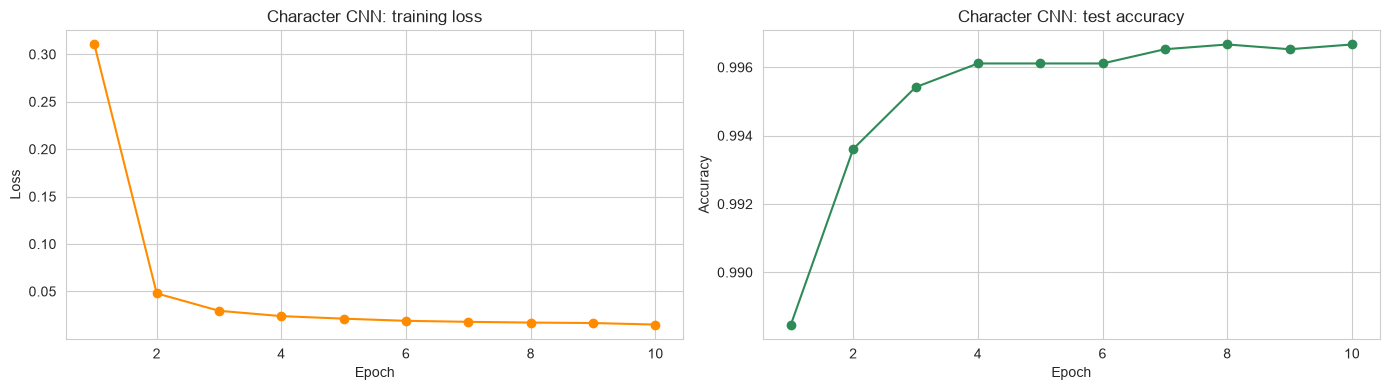

In [60]:
figure, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(range(1, EPOCHS + 1), cnn_loss_history, marker="o", color="darkorange")
axes[0].set_title("Character CNN: training loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")

axes[1].plot(range(1, EPOCHS + 1), cnn_accuracy_history, marker="o", color="seagreen")
axes[1].set_title("Character CNN: test accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")

plt.tight_layout()
plt.show()

In [61]:
cnn_model.eval()

with torch.no_grad():
    cnn_logits = cnn_model(test_characters)
    cnn_probabilities = torch.sigmoid(cnn_logits).numpy()

cnn_predictions = (cnn_probabilities >= 0.5).astype(int)

cnn_result = {
    "Model": "Character CNN on raw URL",
    "Accuracy": accuracy_score(y_test, cnn_predictions),
    "Precision": precision_score(y_test, cnn_predictions),
    "Recall": recall_score(y_test, cnn_predictions),
    "F1": f1_score(y_test, cnn_predictions),
    "ROC_AUC": roc_auc_score(y_test, cnn_probabilities),
}

pd.DataFrame([cnn_result]).set_index("Model").round(4)

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Character CNN on raw URL,0.9967,0.9934,1.0,0.9967,0.9984


### 12.5 Comparing the representations

Putting the four models of this step next to each other answers RQ4 directly: what does
each representation of a website buy, and what does it cost?

In [62]:
representation_table = pd.DataFrame([
    {**mlp_result, "Input": "17 engineered features"},
    {**tfidf_result, "Input": "URL character n-grams"},
    {**bert_result, "Input": "BERT-lite URL embedding"},
    {**cnn_result, "Input": "raw URL characters"},
]).set_index("Model")

representation_table.round(4).sort_values("F1", ascending=False)

,Accuracy,Precision,Recall,F1,ROC_AUC,Input
Model,,,,,,
MLP (engineered features),0.9976,0.9983,0.9969,0.9976,1.0000,17 engineered features
Character CNN on raw URL,0.9967,0.9934,1.0000,0.9967,0.9984,raw URL characters
TF-IDF characters + logistic regression,0.9932,0.9866,1.0000,0.9932,0.9988,URL character n-grams
BERT-lite + MLP head,0.9626,0.9530,0.9733,0.9630,0.9911,BERT-lite URL embedding


<Figure size 1100x400 with 0 Axes>

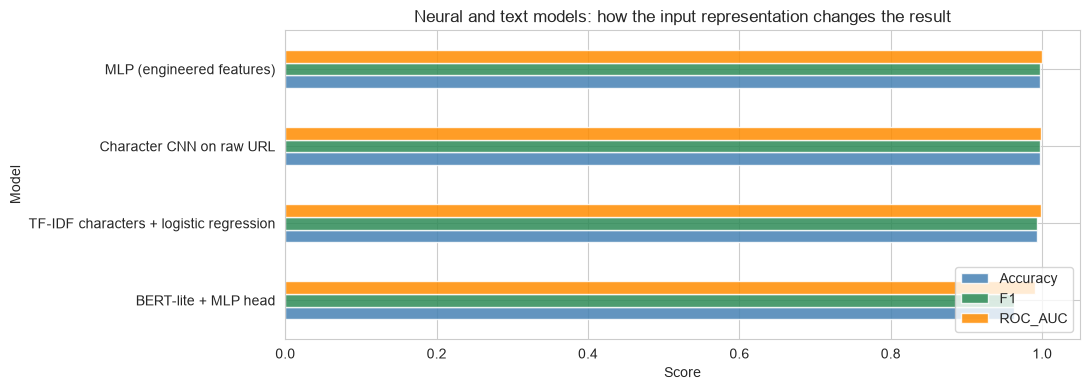

In [63]:
plt.figure(figsize=(11, 4))
representation_table.sort_values("F1")[["Accuracy", "F1", "ROC_AUC"]].plot(
    kind="barh", figsize=(11, 4),
    color=["steelblue", "seagreen", "darkorange"], alpha=0.85
)
plt.title("Neural and text models: how the input representation changes the result")
plt.xlabel("Score")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Step 13: Final comparison of every model

All models are now on the same test set, so their numbers can be compared directly. The
table uses the leak-free feature set for the tabular models, because that is the setting
in which the comparison is meaningful.

In [64]:
test_predictions["MLP (engineered features)"] = mlp_predictions
test_predictions["TF-IDF characters + logistic regression"] = tfidf_predictions
test_predictions["BERT-lite + MLP head"] = bert_predictions
test_predictions["Character CNN on raw URL"] = cnn_predictions

neural_results = pd.DataFrame([
    {**mlp_result, "Group": "Neural network"},
    {**tfidf_result, "Group": "Classical text baseline"},
    {**bert_result, "Group": "Neural network"},
    {**cnn_result, "Group": "Neural network"},
]).set_index("Model")

all_results = pd.concat([results_deploy, neural_results.drop(columns=["Group"])])
all_results = all_results.sort_values("F1", ascending=False).round(4)

all_results

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Hist Gradient Boosting,0.9986,0.9989,0.9983,0.9986,1.0000
Random Forest,0.9986,0.9992,0.9981,0.9986,1.0000
MLP (engineered features),0.9976,0.9983,0.9969,0.9976,1.0000
Logistic Regression,0.9976,0.9978,0.9975,0.9976,1.0000
Character CNN on raw URL,0.9967,0.9934,1.0000,0.9967,0.9984
Perceptron,0.9958,0.9953,0.9964,0.9958,0.9999
k-Nearest Neighbours,0.9956,0.9947,0.9964,0.9956,0.9987
Decision Tree,0.9954,0.9947,0.9961,0.9954,0.9954
TF-IDF characters + logistic regression,0.9932,0.9866,1.0000,0.9932,0.9988


<Figure size 1200x600 with 0 Axes>

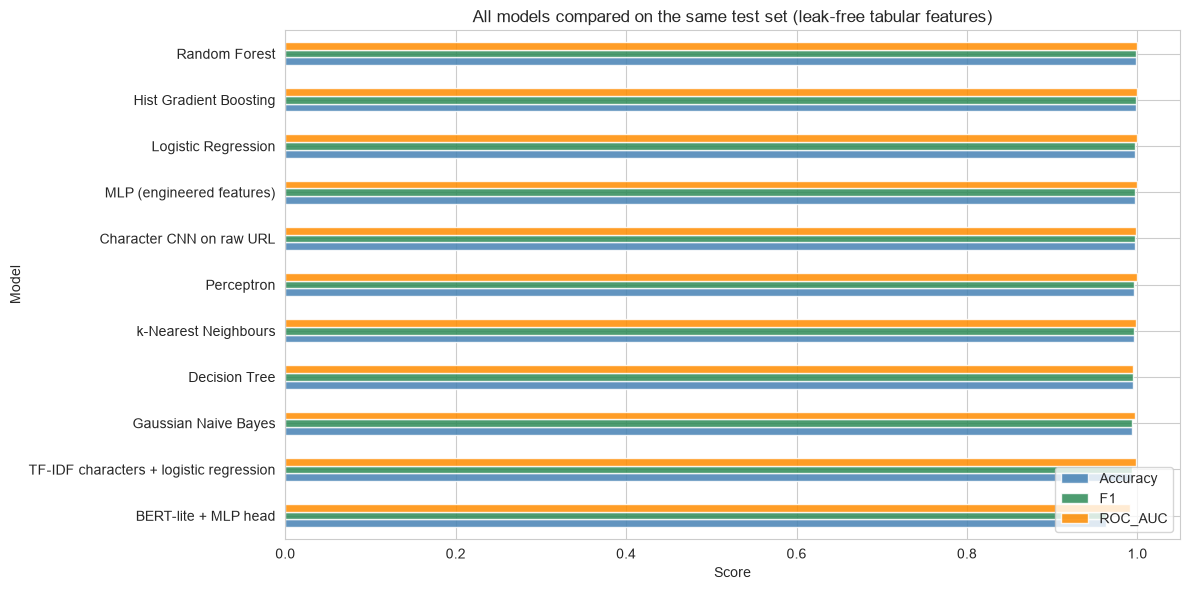

In [65]:
plt.figure(figsize=(12, 6))
all_results.sort_values("F1")[["Accuracy", "F1", "ROC_AUC"]].plot(
    kind="barh", figsize=(12, 6),
    color=["steelblue", "seagreen", "darkorange"], alpha=0.85
)
plt.title("All models compared on the same test set (leak-free tabular features)")
plt.xlabel("Score")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [66]:
best_model_name = all_results.index[0]
print("Best model by F1:", best_model_name)
print()
print(classification_report(y_test, test_predictions[best_model_name],
                            target_names=CLASS_NAMES, digits=4))

Best model by F1: Hist Gradient Boosting

              precision    recall  f1-score   support

    Phishing     0.9983    0.9989    0.9986      3600
  Legitimate     0.9989    0.9983    0.9986      3600

    accuracy                         0.9986      7200
   macro avg     0.9986    0.9986    0.9986      7200
weighted avg     0.9986    0.9986    0.9986      7200



### Saving the results

The tables are written to `Datasets/Results/` so they can be quoted in the report without
being retyped.

In [67]:
results_folder = os.path.join(os.path.dirname(DATA_PATH), "Results")
os.makedirs(results_folder, exist_ok=True)

all_results.to_csv(os.path.join(results_folder, "model_comparison.csv"))
results_ceiling.to_csv(os.path.join(results_folder, "model_comparison_ceiling.csv"))
side_by_side.round(4).to_csv(os.path.join(results_folder, "leakage_ablation.csv"))
clustering_comparison.round(4).to_csv(os.path.join(results_folder, "clustering_comparison.csv"), index=False)
em_sensitivity.round(4).to_csv(os.path.join(results_folder, "em_sensitivity.csv"), index=False)
importance_table.round(4).to_csv(os.path.join(results_folder, "feature_importance.csv"), index=False)
tree_check.round(4).to_csv(os.path.join(results_folder, "decision_tree_check.csv"), index=False)

print("Saved to:", results_folder)
print(os.listdir(results_folder))

Saved to: /Users/sakibdalal/Projects/DMML-CourseWork01/Datasets/Results
['clustering_comparison.csv', 'model_comparison.csv', 'em_sensitivity.csv', 'feature_importance.csv', 'model_comparison_ceiling.csv', 'decision_tree_check.csv', 'leakage_ablation.csv']


# Step 14: Conclusions, limitations and references

### What was found

* **RQ1 - achievable accuracy.** Every tabular model exceeds 99% accuracy on the leak-free
  feature set, with the two boosted/bagged ensembles at 99.86%, and the best model of the
  whole project (Histogram Gradient Boosting) reaching F1 = 0.9986. The task, as captured
  by this dataset, is close to separable - which is itself the headline finding, and the
  reason the discussion focuses on representation and on honesty about features rather than
  on squeezing out another decimal place. Hypothesis H1 is supported.
* **RQ2 - which features carry the signal.** Page-level and structural features dominate:
  page size, the reference counters, and the boilerplate flags such as `HasSocialNet`,
  `HasCopyrightInfo` and `HasDescription`. The cheap lexical counts are present but never
  at the top, and plain URL length is a far weaker signal than folklore suggests - it never
  reaches the top ten on its own. `HasPasswordField` turns out to be more common on
  legitimate pages, which is the kind of surprise only EDA surfaces. Hypothesis H2 is
  supported.
* **RQ3 - unsupervised structure.** K-Means recovers the two classes with an adjusted Rand
  index of 0.88 and the Gaussian mixture reaches 0.92, so hypothesis H3 is *not* supported -
  the clusters line up far better than expected. The interesting finding is not the score
  but the fragility of EM: the same model swings from near-perfect to a degenerate collapse
  depending on how it is initialised, and a good silhouette score can accompany a worthless
  partition. Clustering can describe groups; only a supervised model can say which group is
  the dangerous one.
* **RQ4 - neural networks.** On the engineered features the MLP reaches F1 = 0.9976, which
  matches the linear model and sits just below the ensembles - supporting H4 that a network
  does not clearly win on this data. On the raw URL text the character CNN reaches 0.9967,
  the plain TF-IDF baseline 0.9932, and the frozen BERT-lite embedding only 0.9630. The
  ranking is the opposite of what "use a pretrained model" intuition would suggest, and it
  has a clear explanation: a two-layer BERT's mean-pooled vector is a 128-number summary
  that discards the character detail a convolutional filter or an n-gram count keeps. A
  pretrained model is not automatically a better representation.

### The main takeaway for a security team

Two things matter more than the choice of classifier.

First, **how much of the page you are allowed to see**. The features that carry the signal
are the ones that describe the page's structure, not its address. A URL-only detector is
cheap but limited.

Second, **how honest the features are**. The strongest single column in this dataset,
`URLSimilarityIndex`, is close to a restatement of the label. Here removing it costs
almost nothing, because the remaining page features reconstruct nearly the same decision -
but the analyst only knows that *after* running the ablation. A team that reported the
ceiling number alone would have no idea whether its detector worked for the right reason,
and on a different dataset the same column would inflate the score substantially.

### Limitations

1. **Sampling.** Models were trained on a 24,000-row stratified sample rather than the
   full 235,370 rows, to keep the notebook runnable on a laptop. The conclusions about
   which feature families matter are unaffected, but absolute scores would shift slightly
   on the full data.
2. **Same-period data.** All examples come from one collection effort. Phishing changes
   quickly, so a model trained on this file will decay as campaigns change. The honest
   evaluation for deployment is a temporal split - train on older captures, test on newer
   ones - which this dataset does not support well.
3. **Label noise.** Whether a site is "legitimate" is a judgement made by the dataset
   creator. Look-alike sites that are not malicious, and legitimate sites with poor
   practice, blur the boundary.
4. **Frozen BERT.** The BERT weights were not fine-tuned. With more data and a GPU, full
   fine-tuning of the upper layers would probably help, and it is the obvious next step
   for RQ4.
5. **No external reputation features.** Who registered the domain, when, and how the site
   is linked from elsewhere are strong phishing signals that this dataset does not include.

### Future work

* Train on the full dataset and on a temporal split.
* Add WHOIS and passive DNS features.
* Calibrate the classifier so its output is a usable probability, and tune the threshold
  against the real cost of a missed phishing site versus a false alarm.
* Fine-tune the upper BERT layers on the URL text rather than freezing them.

### References

1. Prasad, A. and Chandra, S. (2024) *PhiUSIIL: A diverse security profile empowered
   phishing URL detection framework based on similarity index and incremental learning*.
   Computers and Security, 136, 103545. Dataset: UCI Machine Learning Repository, ID 967,
   licence CC BY 4.0. https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset
2. Hannousse, A. and Yahiouche, S. (2021) *Towards benchmark datasets for machine learning
   based website phishing detection*. Computer Networks, 199, 108466.
3. Devlin, J., Chang, M.-W., Lee, K. and Toutanova, K. (2019) *BERT: Pre-training of Deep
   Bidirectional Transformers for Language Understanding*. NAACL-HLT.
4. Breiman, L. (2001) *Random Forests*. Machine Learning, 45, pp. 5-32.
5. Turc, I., Chang, M.-W., Lee, K. and Toutanova, K. (2019) *Well-Read Students Learn
   Better: On the Importance of Pre-training Compact Models*. arXiv:1908.08962. The source
   of the `L-2_H-128_A-2` small BERT used here.
6. Pedregosa, F. et al. (2011) *Scikit-learn: Machine Learning in Python*. Journal of
   Machine Learning Research, 12, pp. 2825-2830.

### Generative AI disclosure

The code in this notebook was produced with the assistance of a generative AI tool. The
prompt used was a request to implement the F21DL group coursework requirements R1-R4 in a
single Jupyter notebook using the PhiUSIIL dataset, plain pandas and scikit-learn, and the
small BERT model installed locally. All code was executed, and its output was reviewed and
interpreted by the author, in line with Framework Statement 6 of the coursework's
generative AI policy.

---

### Thank you

This notebook contains the complete implementation of requirements R1 to R4 for Topic 11:
predicting whether a website is fraudulent or a scam.